In [1]:
## library imports
import numpy as np 
import matplotlib.pyplot as plt 
from astropy.io import fits
from astropy.table import Table, unique
import glob
import os
import astro_functions
from halpha_fit import narrow_fit_ha

## global constants 

ha_line = 0.6564614 # microns
hb_line = 0.4862721 # microns
o3_line = 0.5008239 # microns 

g235h_wv_range = np.array([1.66, 3.17])
g395h_wv_range = np.array([2.87, 5.27])

In [2]:
## redshift catalog for sources 
oceans_redshifts = Table.read("/Users/madisynbrooks/Documents/OCEANS/OCEANS_CEERS_v1.0cat_DB_catalog_full.fits")
oceans_redshifts.colnames

['Cox_v10_number',
 'zspec',
 'oceans_id',
 'logM_50',
 'logM_16',
 'logM_84',
 'logSFRinst_50',
 'logSFRinst_16',
 'logSFRinst_84',
 'logZsol_50',
 'logZsol_16',
 'logZsol_84',
 'Av_50',
 'Av_16',
 'Av_84',
 'zfit_50',
 'zfit_16',
 'zfit_84',
 'logMt_50',
 'logMt_16',
 'logMt_84',
 'logSFRtuple_50',
 'logSFRtuple_16',
 'logSFRtuple_84',
 'logSFR10_50',
 'logSFR10_16',
 'logSFR10_84',
 'logSFR100_50',
 'logSFR100_16',
 'logSFR100_84',
 'logSFR300_50',
 'logSFR300_16',
 'logSFR300_84',
 'logSFR1000_50',
 'logSFR1000_16',
 'logSFR1000_84',
 't25_50',
 't25_16',
 't25_84',
 't50_50',
 't50_16',
 't50_84',
 't75_50',
 't75_16',
 't75_84',
 'sfh_50',
 'sfh_16',
 'sfh_84',
 'timeax',
 'obs_sed',
 'obs_err',
 'bf_sed',
 'sed_rf',
 'bf_lam',
 'bf_spec',
 'posterior_sample_ids',
 'nparam',
 'nbands',
 'chi2',
 'fit_flags']

In [3]:
len(oceans_redshifts)

205

In [4]:
## i know the redshift for source 20504 is wrong, so I am going to manually update it in the catalog 
row = oceans_redshifts['oceans_id'] == 20504

In [5]:
oceans_redshifts[row]

Cox_v10_number,zspec,oceans_id,logM_50,logM_16,logM_84,logSFRinst_50,logSFRinst_16,logSFRinst_84,logZsol_50,logZsol_16,logZsol_84,Av_50,Av_16,Av_84,zfit_50,zfit_16,zfit_84,logMt_50,logMt_16,logMt_84,logSFRtuple_50,logSFRtuple_16,logSFRtuple_84,logSFR10_50,logSFR10_16,logSFR10_84,logSFR100_50,logSFR100_16,logSFR100_84,logSFR300_50,logSFR300_16,logSFR300_84,logSFR1000_50,logSFR1000_16,logSFR1000_84,t25_50,t25_16,t25_84,t50_50,t50_16,t50_84,t75_50,t75_16,t75_84,sfh_50,sfh_16,sfh_84,timeax,obs_sed,obs_err,bf_sed,sed_rf,bf_lam,bf_spec,posterior_sample_ids,nparam,nbands,chi2,fit_flags
int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64[100],float64[100],float64[100],float64[100],float64[14],float64[14],float64[14],float64[20],float64[5994],float64[5994],float64[1000],float64,float64,float64,float64
26478,7.2306,20504.0,10.574500000002196,--,10.574500000002196,3.0325000000030164,3.0325000000030164,3.1225000000030465,-0.7255000000000853,-0.7255000000000853,-0.5515000000001045,2.4445,2.4445,2.4615,7.200523943290917,7.200523943290917,7.271523943290917,10.629500000002215,--,10.629500000002215,3.0325000000030164,3.0325000000030164,3.121500000003047,3.022416416099506,3.022416416099506,3.0841496664334858,2.63465669912417,--,2.63465669912417,2.1571628156065485,--,2.1571628156065485,1.7808646394593655,--,1.7808646394593655,0.3665,0.3665,0.9515,0.5135,0.5135,0.9724999999999999,0.9205,0.9205,0.9874999999999999,5.742657790966485 .. 901.6222769245467,3.6165684809447565 .. 901.6222769245467,5.742657790966485 .. 1183.879342442719,0.0 .. 0.7234832285559532,0.042969142913818356 .. --,0.0038201920135162897 .. --,0.026505792374560373 .. 1.698935904927846e-36,33.7401034548302 .. 2065.219261008019,0.07527184315746961 .. 82716.31116205451,2.3581381780449795e-65 .. 5453.996784243624,972619.0 .. 972619.0,3.0,11.0,32.45129443086762,0.0
26478,7.2307,20504.0,10.574500000002196,--,10.574500000002196,3.0325000000030164,3.0325000000030164,3.1225000000030465,-0.7255000000000853,-0.7255000000000853,-0.5515000000001045,2.4445,2.4445,2.4615,7.200523943290917,7.200523943290917,7.271523943290917,10.629500000002215,--,10.629500000002215,3.0325000000030164,3.0325000000030164,3.121500000003047,3.022416416099506,3.022416416099506,3.0841496664334858,2.63465669912417,--,2.63465669912417,2.1571628156065485,--,2.1571628156065485,1.7808646394593655,--,1.7808646394593655,0.3665,0.3665,0.9515,0.5135,0.5135,0.9724999999999999,0.9205,0.9205,0.9874999999999999,5.742657790966485 .. 901.6222769245467,3.6165684809447565 .. 901.6222769245467,5.742657790966485 .. 1183.879342442719,0.0 .. 0.7234832285559532,0.042969142913818356 .. --,0.0038201920135162897 .. --,0.026505792374560373 .. 1.698935904927846e-36,33.7401034548302 .. 2065.219261008019,0.07527184315746961 .. 82716.31116205451,2.3581381780449795e-65 .. 5453.996784243624,972619.0 .. 972619.0,3.0,11.0,32.45129443086762,0.0


In [6]:
oceans_redshifts['zspec'][row] = 5.276

In [7]:
oceans_redshifts[row]

Cox_v10_number,zspec,oceans_id,logM_50,logM_16,logM_84,logSFRinst_50,logSFRinst_16,logSFRinst_84,logZsol_50,logZsol_16,logZsol_84,Av_50,Av_16,Av_84,zfit_50,zfit_16,zfit_84,logMt_50,logMt_16,logMt_84,logSFRtuple_50,logSFRtuple_16,logSFRtuple_84,logSFR10_50,logSFR10_16,logSFR10_84,logSFR100_50,logSFR100_16,logSFR100_84,logSFR300_50,logSFR300_16,logSFR300_84,logSFR1000_50,logSFR1000_16,logSFR1000_84,t25_50,t25_16,t25_84,t50_50,t50_16,t50_84,t75_50,t75_16,t75_84,sfh_50,sfh_16,sfh_84,timeax,obs_sed,obs_err,bf_sed,sed_rf,bf_lam,bf_spec,posterior_sample_ids,nparam,nbands,chi2,fit_flags
int32,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64[100],float64[100],float64[100],float64[100],float64[14],float64[14],float64[14],float64[20],float64[5994],float64[5994],float64[1000],float64,float64,float64,float64
26478,5.276,20504.0,10.574500000002196,--,10.574500000002196,3.0325000000030164,3.0325000000030164,3.1225000000030465,-0.7255000000000853,-0.7255000000000853,-0.5515000000001045,2.4445,2.4445,2.4615,7.200523943290917,7.200523943290917,7.271523943290917,10.629500000002215,--,10.629500000002215,3.0325000000030164,3.0325000000030164,3.121500000003047,3.022416416099506,3.022416416099506,3.0841496664334858,2.63465669912417,--,2.63465669912417,2.1571628156065485,--,2.1571628156065485,1.7808646394593655,--,1.7808646394593655,0.3665,0.3665,0.9515,0.5135,0.5135,0.9724999999999999,0.9205,0.9205,0.9874999999999999,5.742657790966485 .. 901.6222769245467,3.6165684809447565 .. 901.6222769245467,5.742657790966485 .. 1183.879342442719,0.0 .. 0.7234832285559532,0.042969142913818356 .. --,0.0038201920135162897 .. --,0.026505792374560373 .. 1.698935904927846e-36,33.7401034548302 .. 2065.219261008019,0.07527184315746961 .. 82716.31116205451,2.3581381780449795e-65 .. 5453.996784243624,972619.0 .. 972619.0,3.0,11.0,32.45129443086762,0.0
26478,5.276,20504.0,10.574500000002196,--,10.574500000002196,3.0325000000030164,3.0325000000030164,3.1225000000030465,-0.7255000000000853,-0.7255000000000853,-0.5515000000001045,2.4445,2.4445,2.4615,7.200523943290917,7.200523943290917,7.271523943290917,10.629500000002215,--,10.629500000002215,3.0325000000030164,3.0325000000030164,3.121500000003047,3.022416416099506,3.022416416099506,3.0841496664334858,2.63465669912417,--,2.63465669912417,2.1571628156065485,--,2.1571628156065485,1.7808646394593655,--,1.7808646394593655,0.3665,0.3665,0.9515,0.5135,0.5135,0.9724999999999999,0.9205,0.9205,0.9874999999999999,5.742657790966485 .. 901.6222769245467,3.6165684809447565 .. 901.6222769245467,5.742657790966485 .. 1183.879342442719,0.0 .. 0.7234832285559532,0.042969142913818356 .. --,0.0038201920135162897 .. --,0.026505792374560373 .. 1.698935904927846e-36,33.7401034548302 .. 2065.219261008019,0.07527184315746961 .. 82716.31116205451,2.3581381780449795e-65 .. 5453.996784243624,972619.0 .. 972619.0,3.0,11.0,32.45129443086762,0.0


In [8]:
oceans_redshifts = oceans_redshifts['oceans_id', 'zspec']

In [9]:
## removing duplicates from the redshift catalog, sources were observed more than one time 
oceans_redshifts = unique(oceans_redshifts, keys = 'oceans_id')

In [10]:
oceans_redshifts

oceans_id,zspec
float64,float64
462.0,4.1427
597.0,3.151
1459.0,4.9465
1613.0,4.2807
1781.0,4.3493
1785.0,8.3299
1794.0,3.6817
1994.0,5.4228
2255.0,2.9669


s000000462
fitting the halpha line...
---------------------------


100%|██████████| 20000/20000 [00:23<00:00, 854.78it/s]


plotting fit...
saving halpha fit...
------------------------------
s000000597
fitting the halpha line...
---------------------------


100%|██████████| 20000/20000 [00:17<00:00, 1132.78it/s]


plotting fit...
saving halpha fit...
------------------------------
s000001459
fitting the halpha line...
---------------------------


...

plotting fit...
saving halpha fit...
------------------------------
s000163117
fitting the halpha line...
---------------------------


100%|██████████| 20000/20000 [00:21<00:00, 928.52it/s]


plotting fit...
saving halpha fit...
------------------------------
s000169018
No halpha wv coverage... 
------------------------------
s000169045
fitting the halpha line...
---------------------------


100%|██████████| 20000/20000 [00:24<00:00, 829.49it/s]


plotting fit...
saving halpha fit...
------------------------------


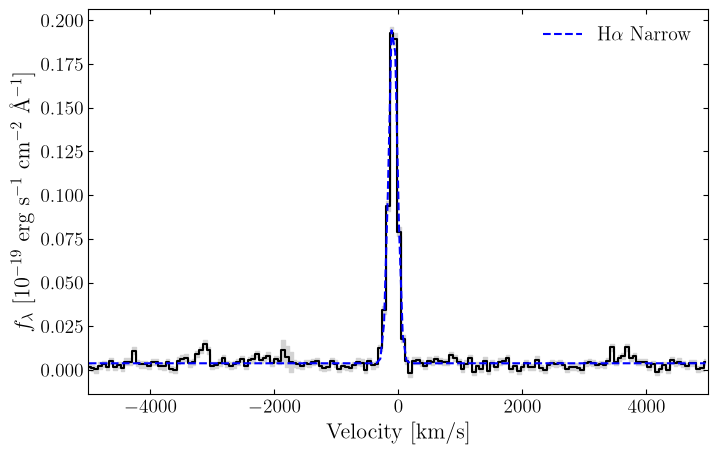

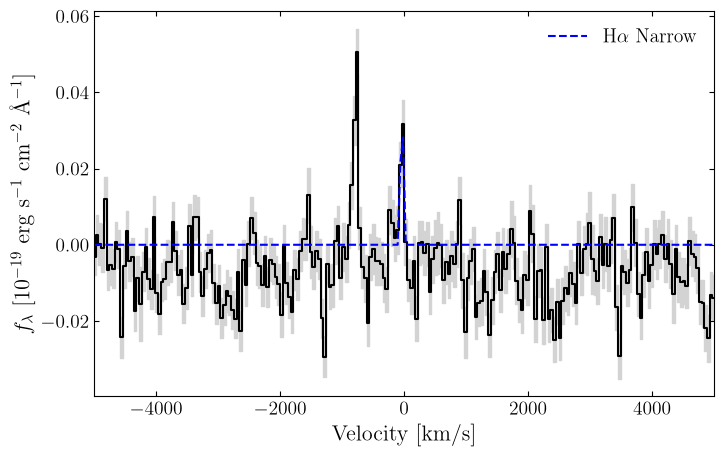

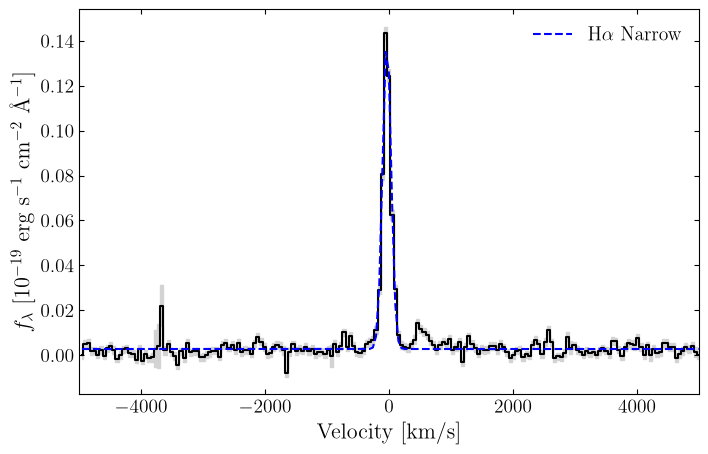

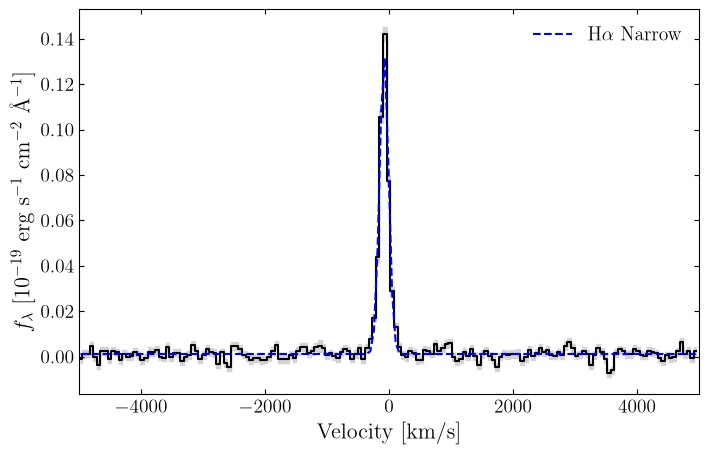

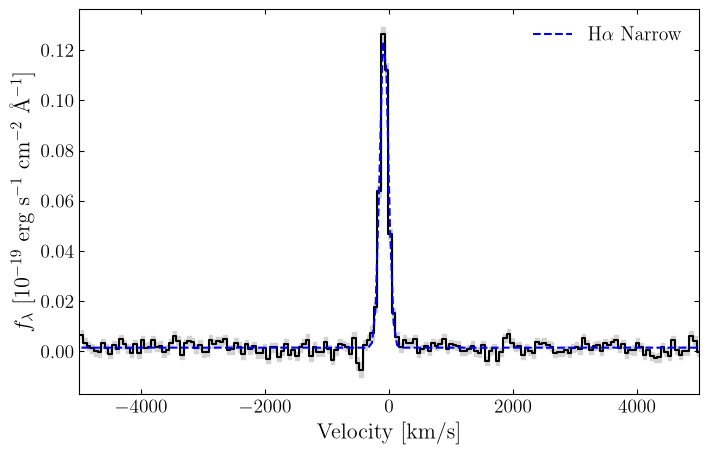

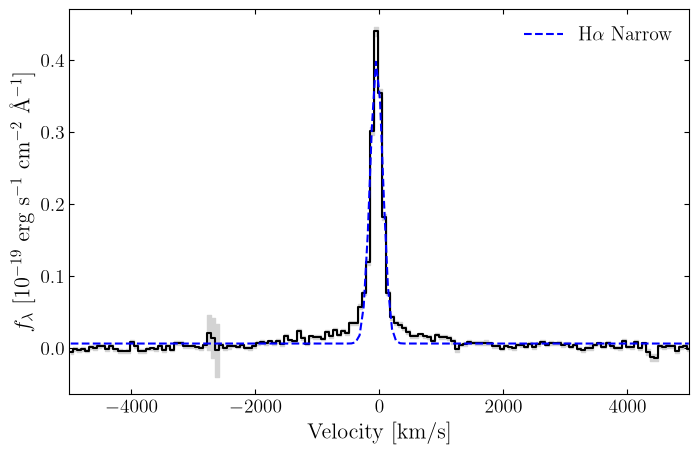

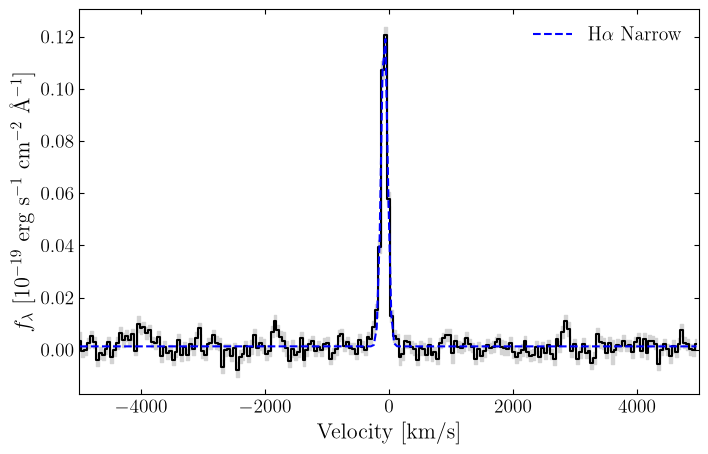

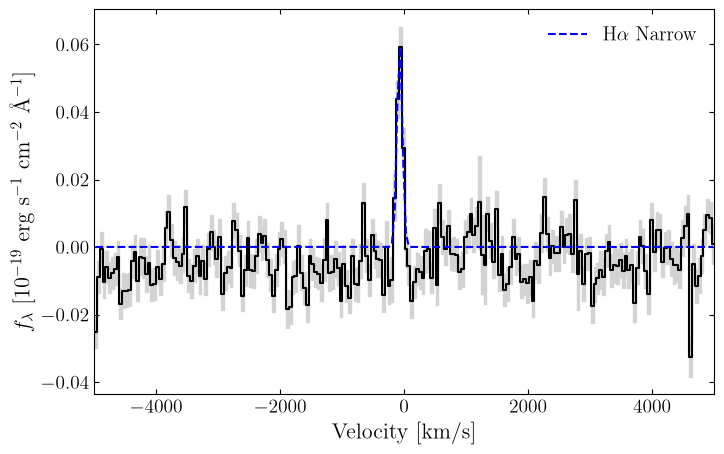

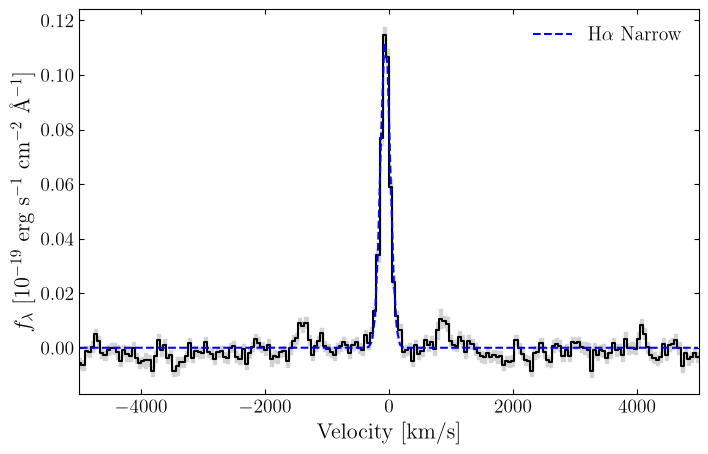

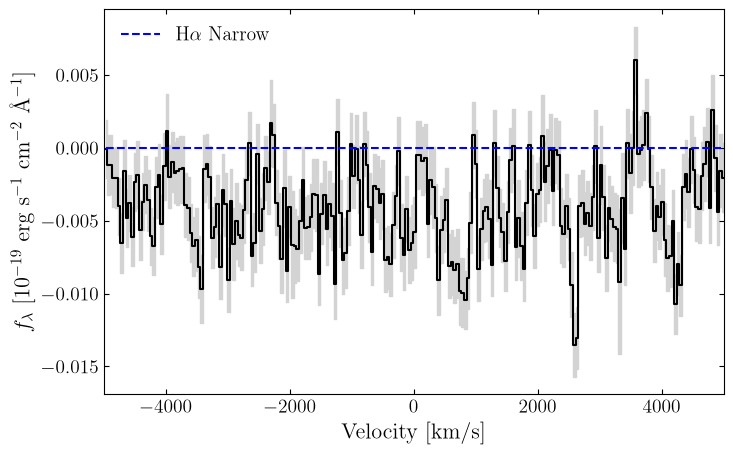

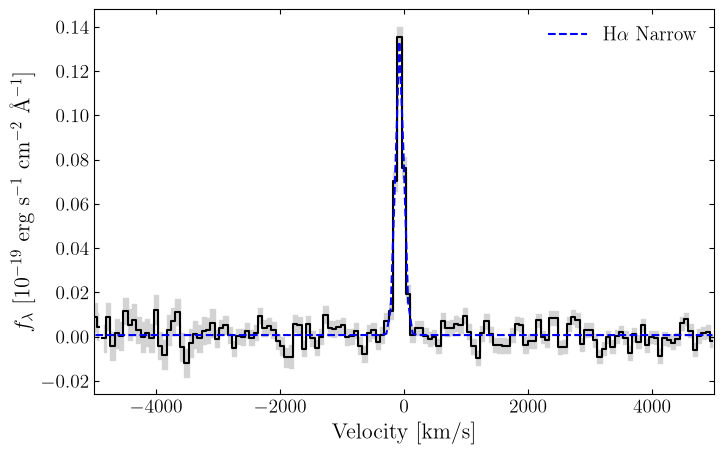

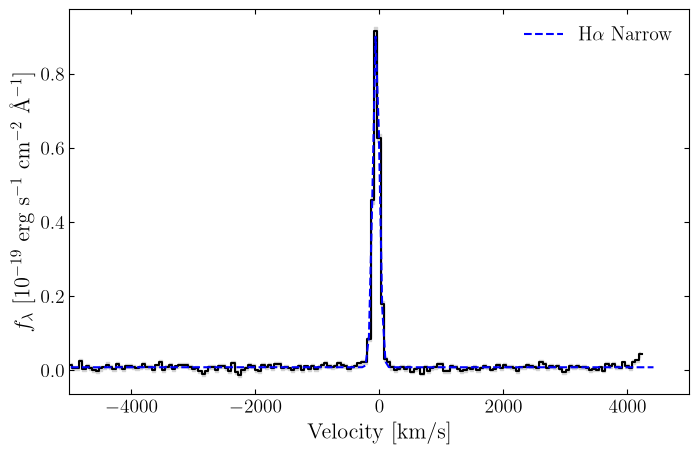

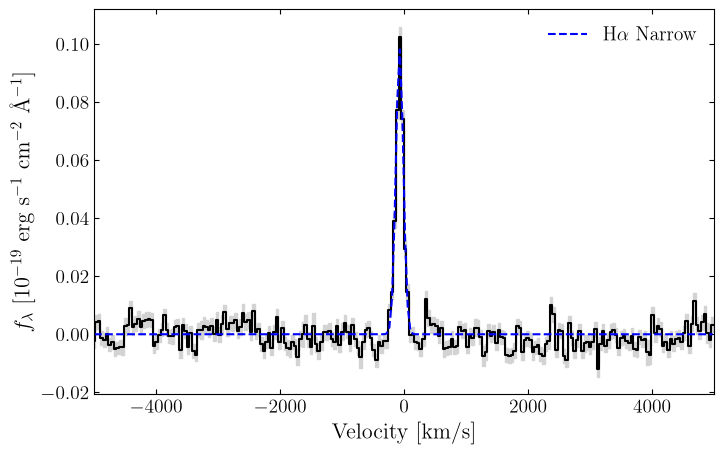

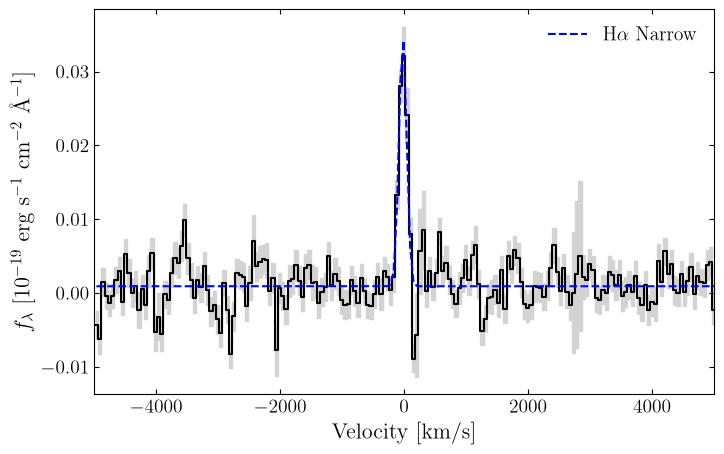

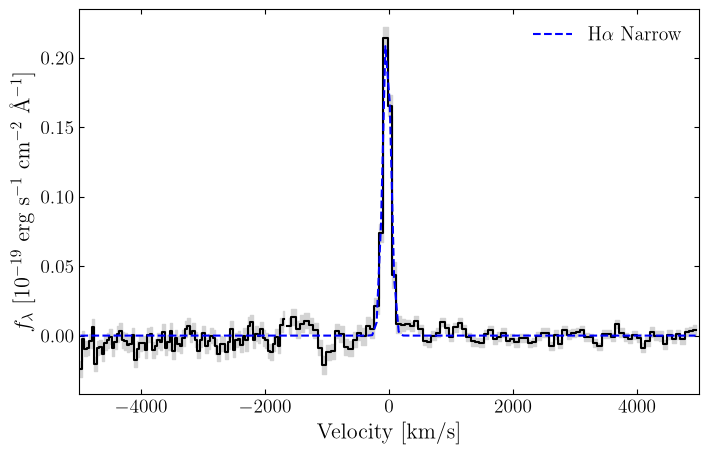

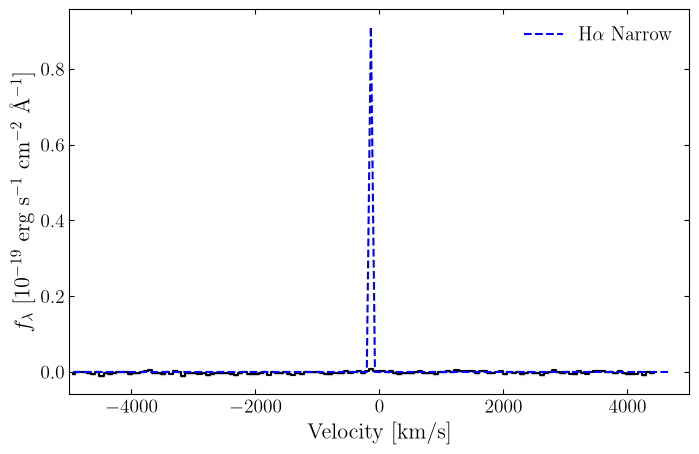

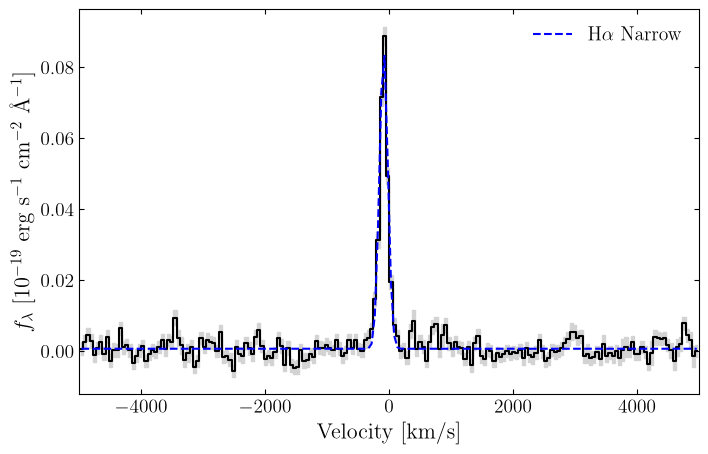

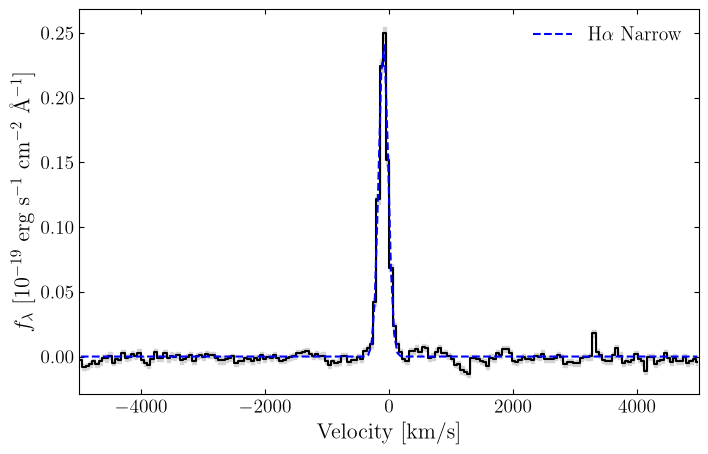

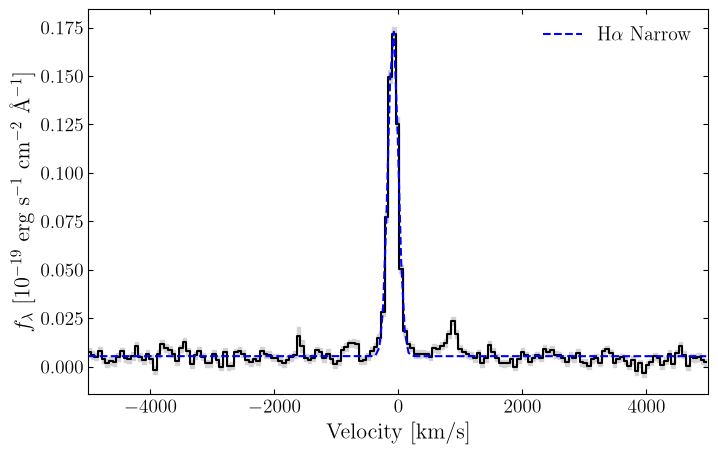

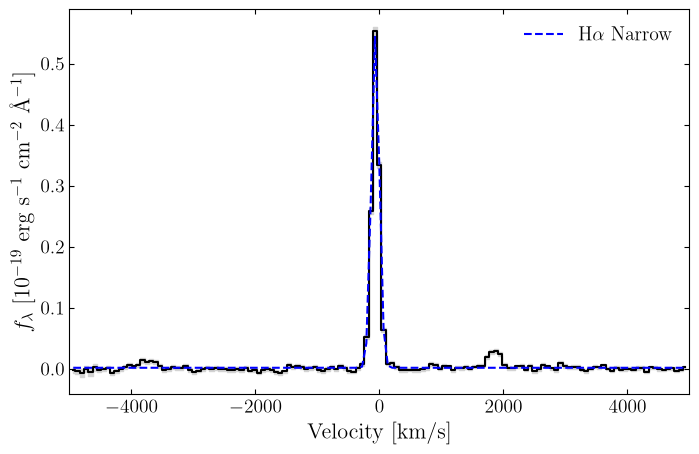

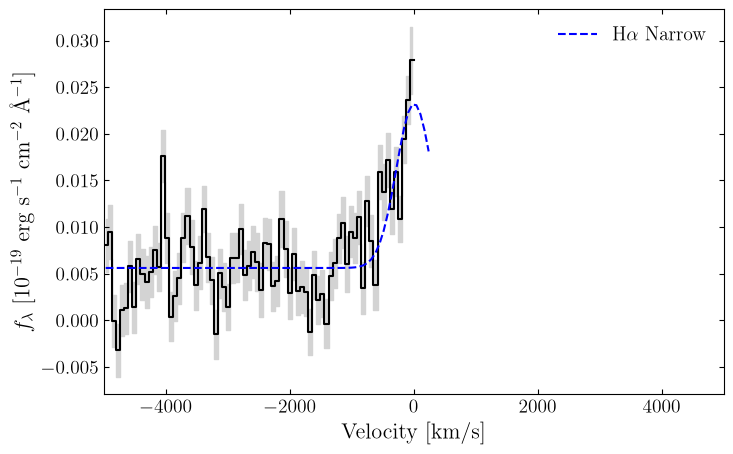

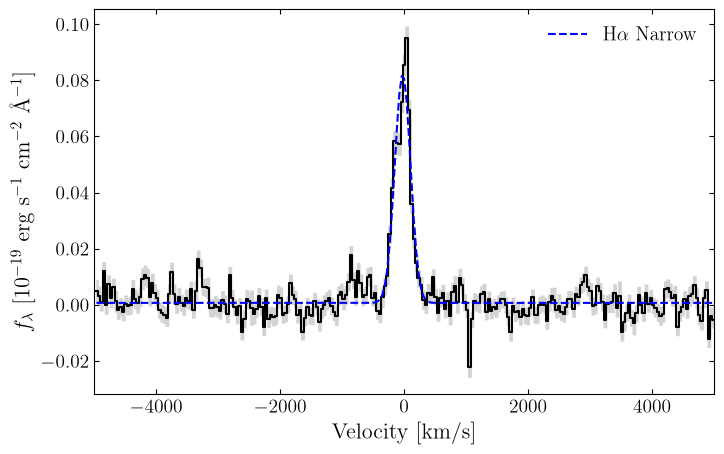

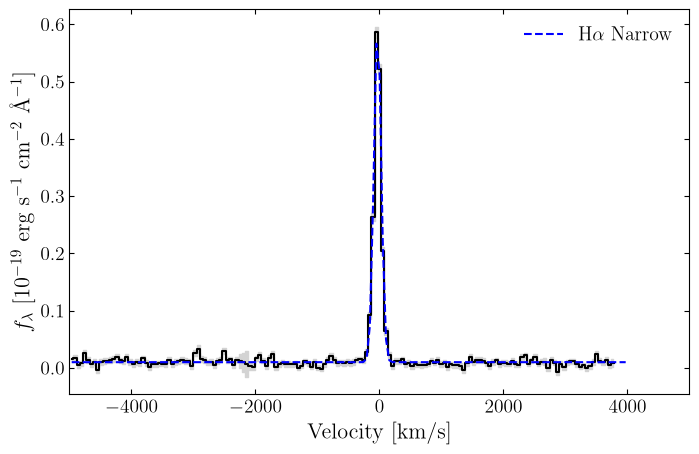

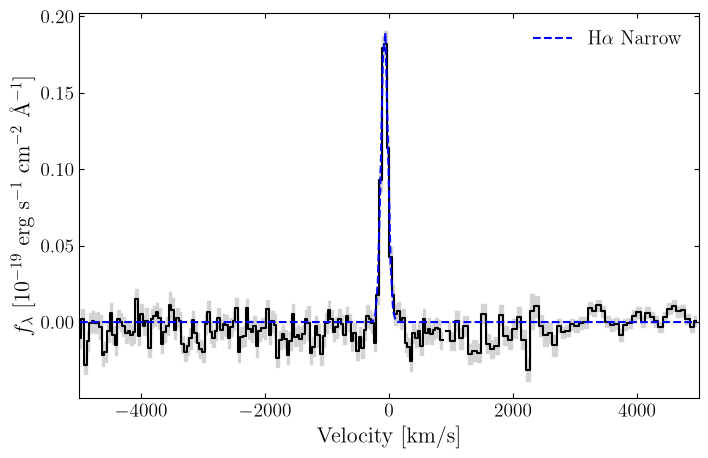

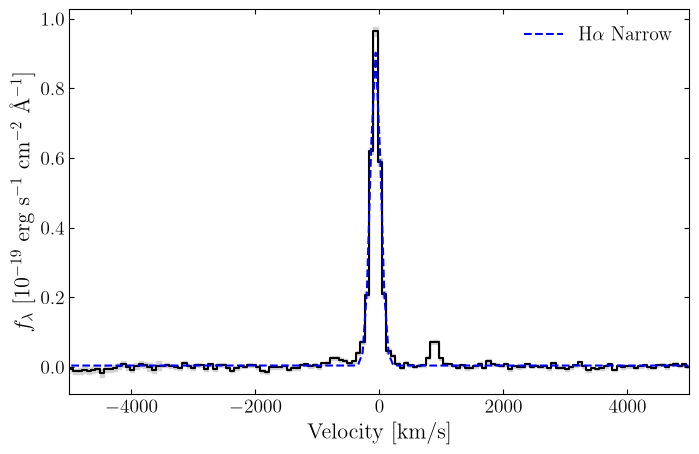

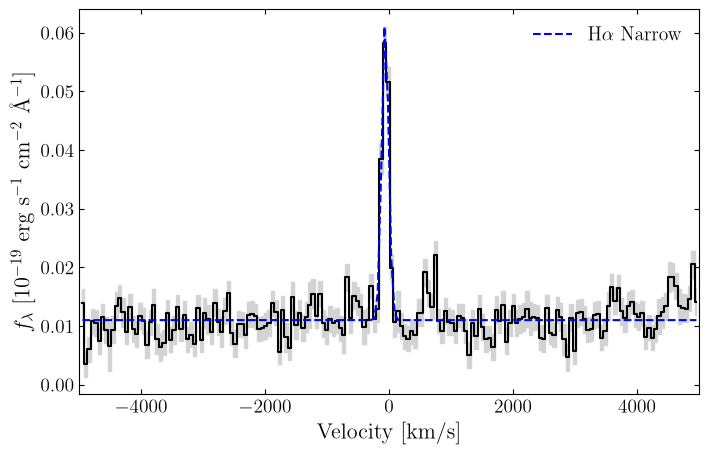

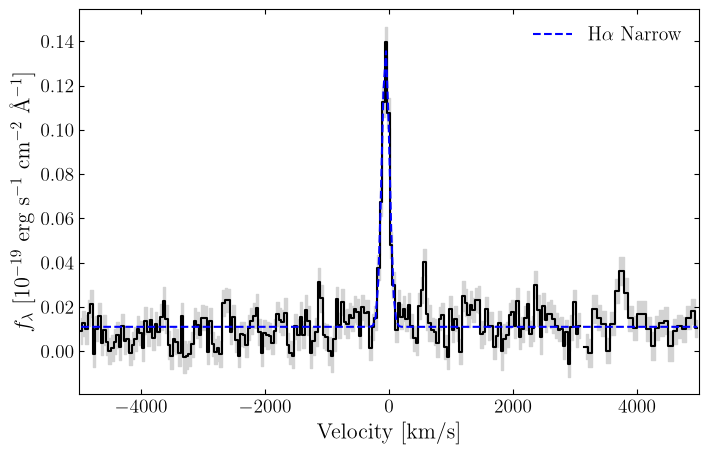

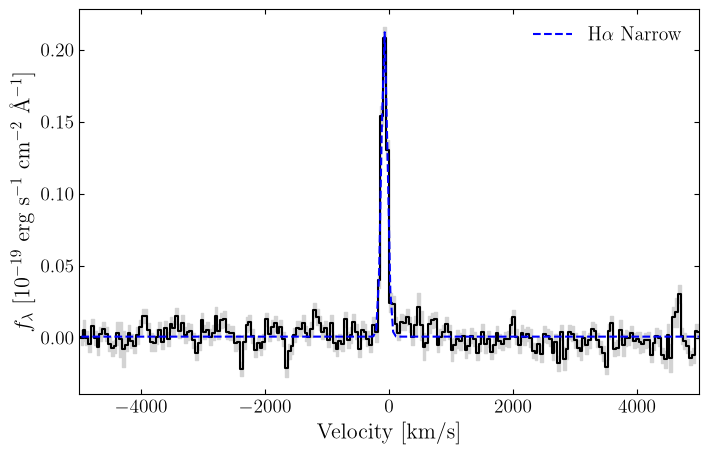

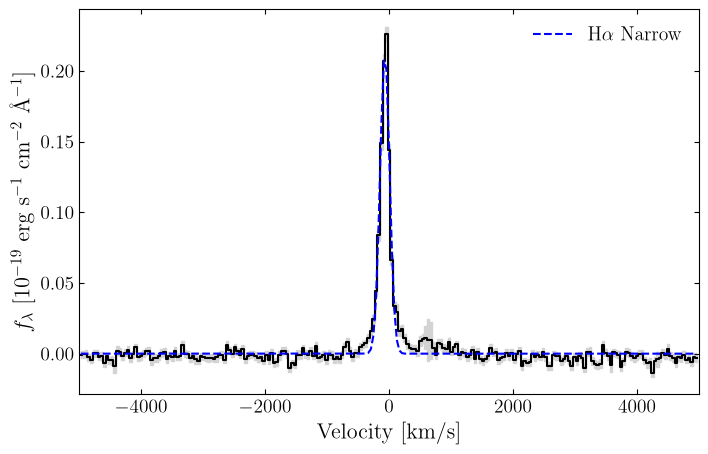

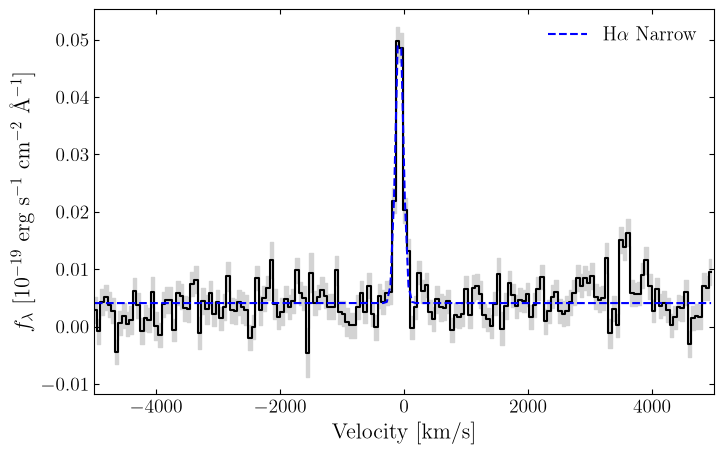

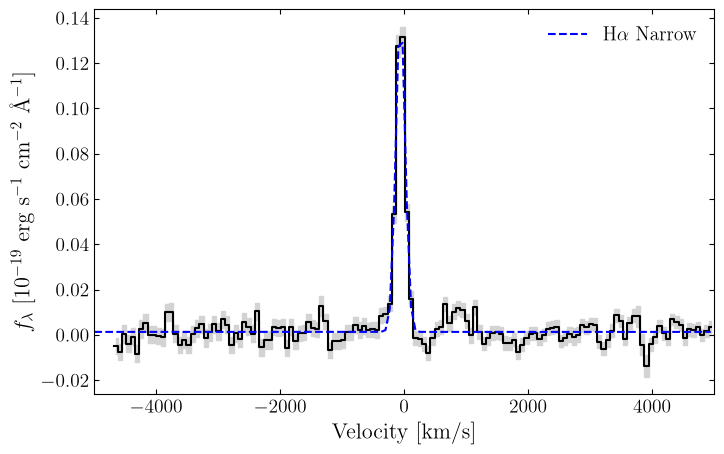

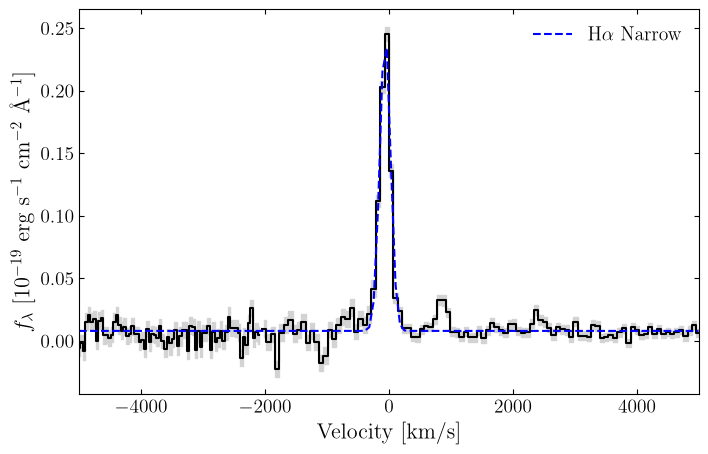

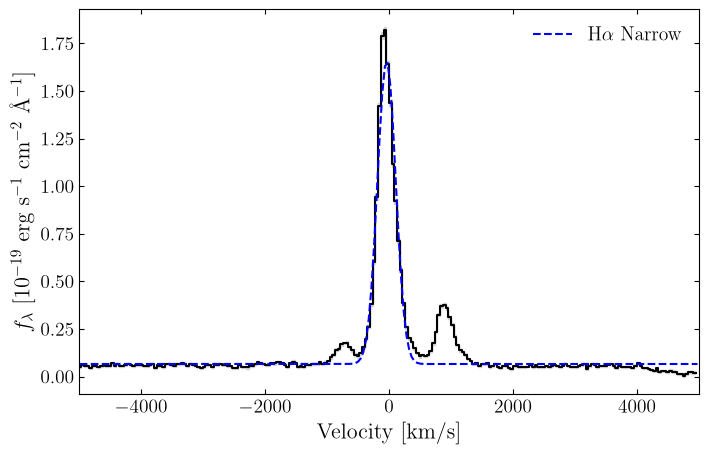

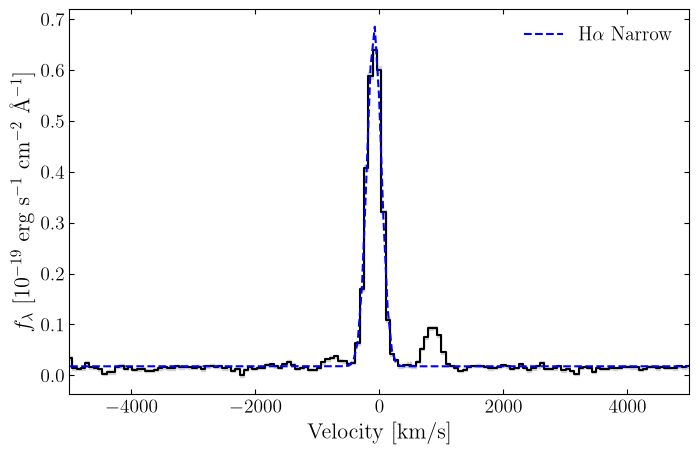

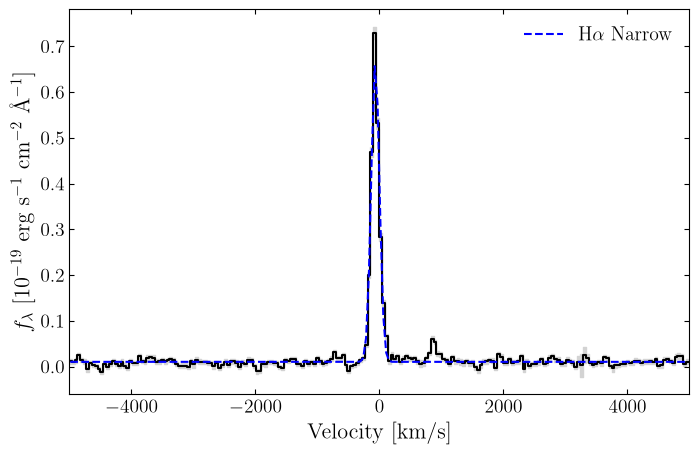

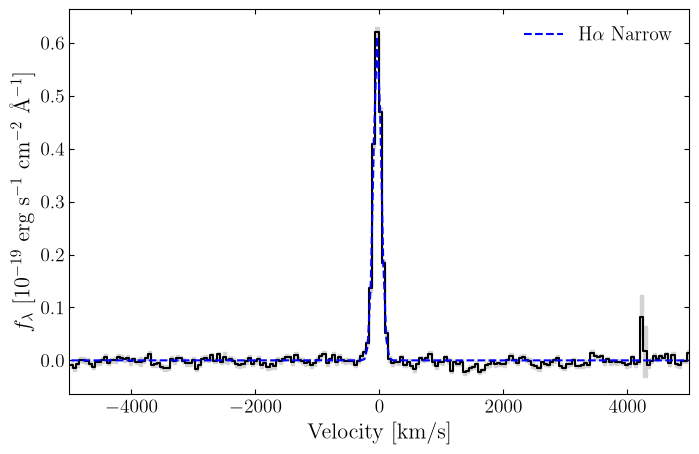

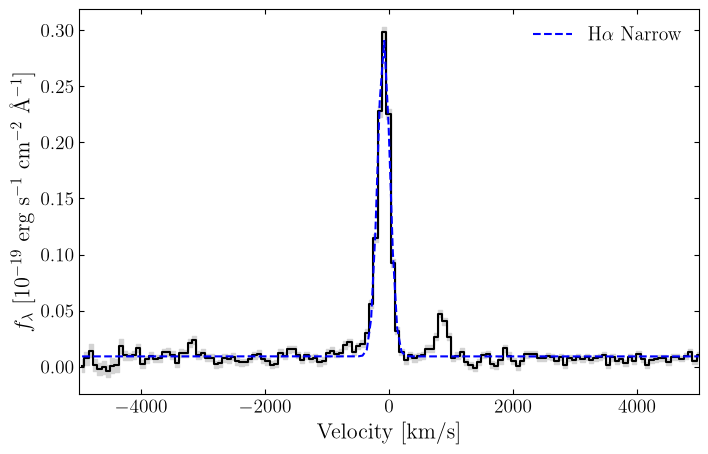

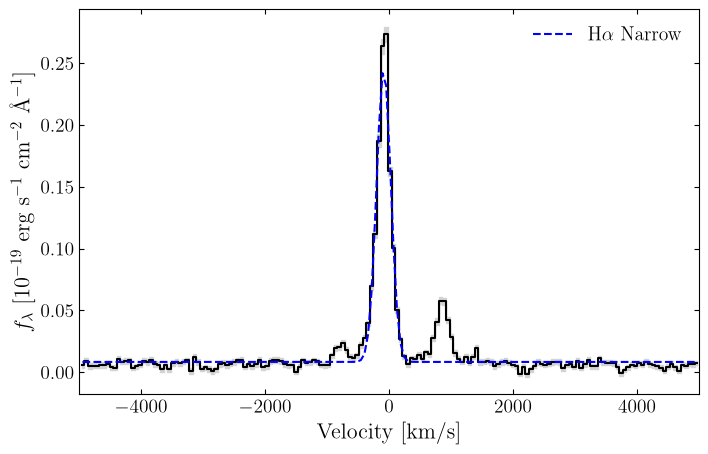

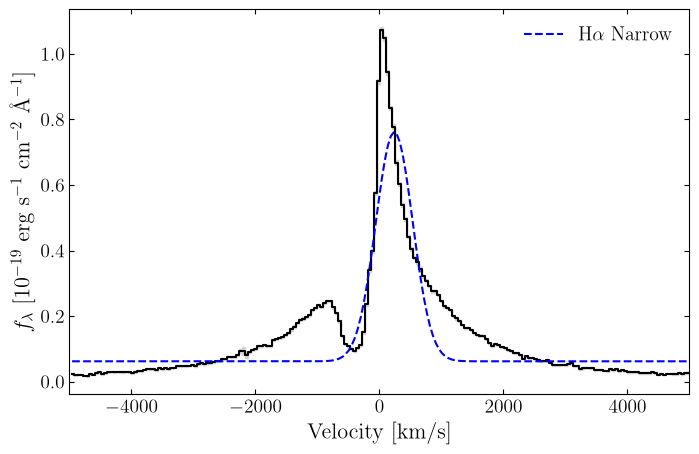

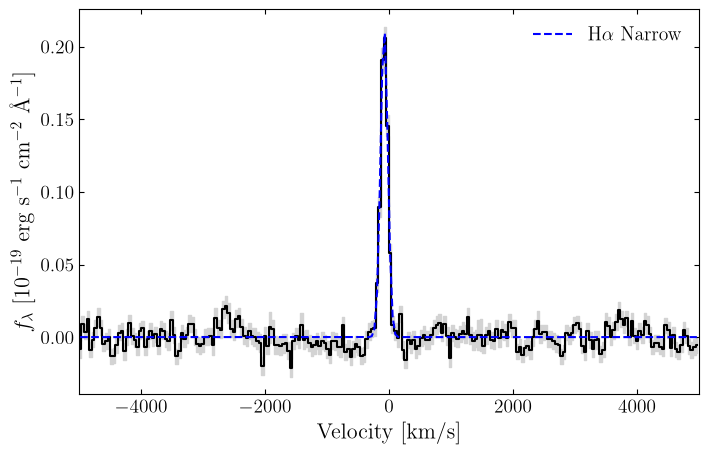

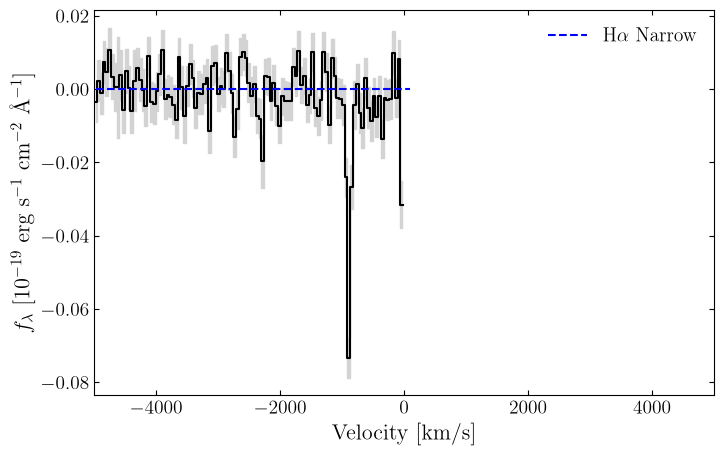

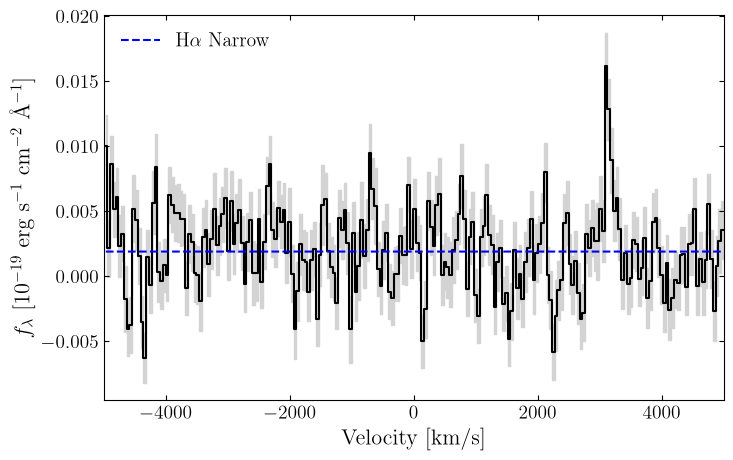

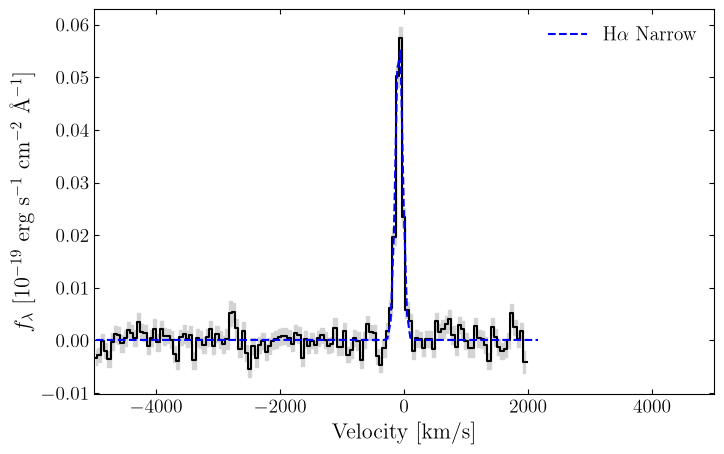

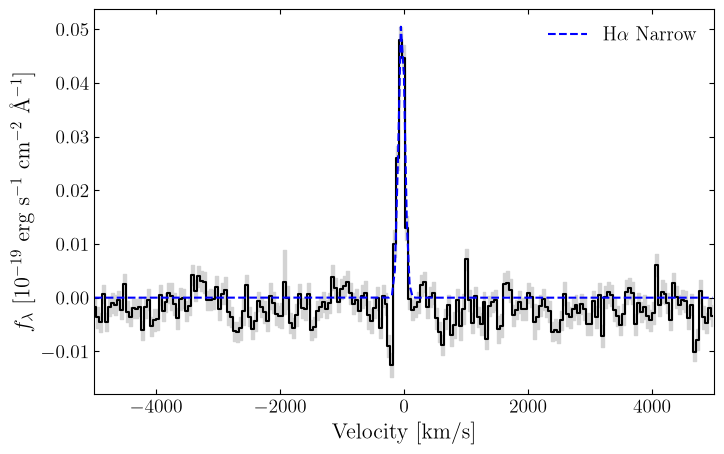

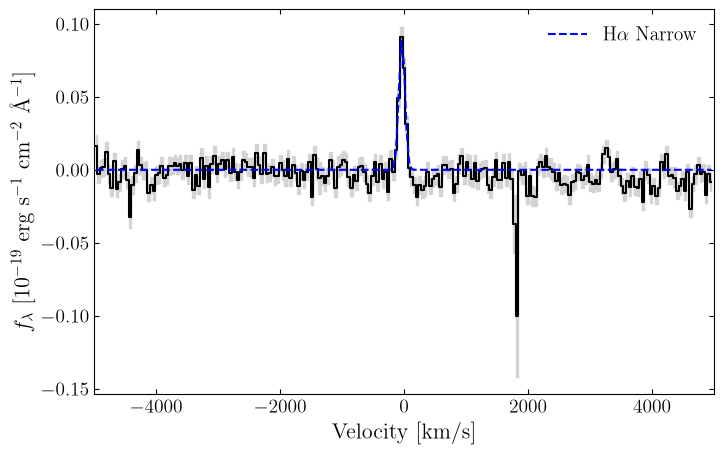

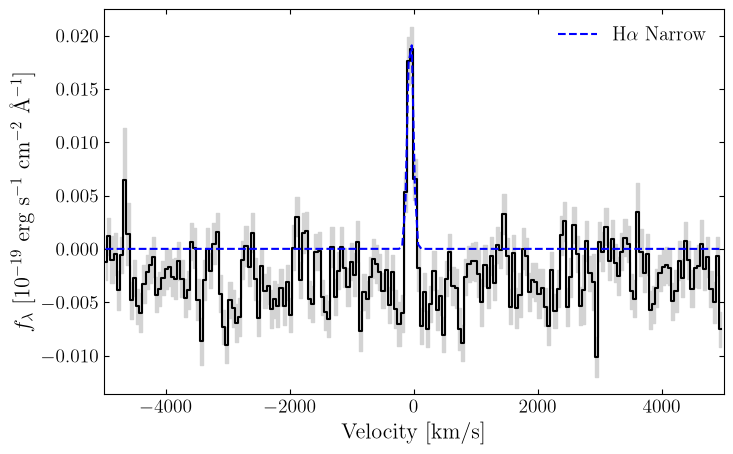

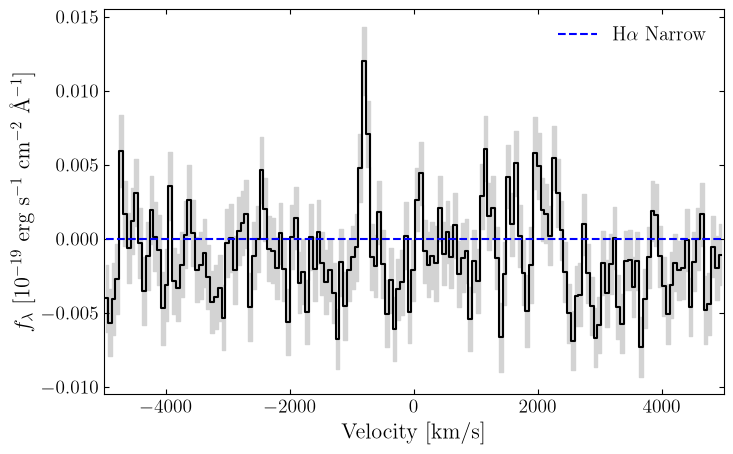

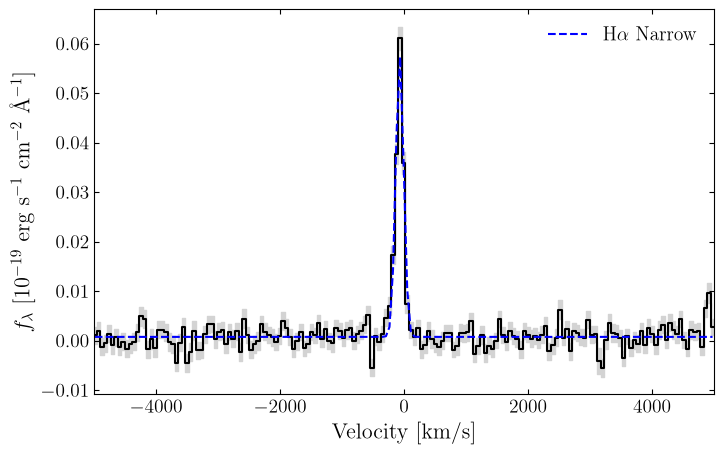

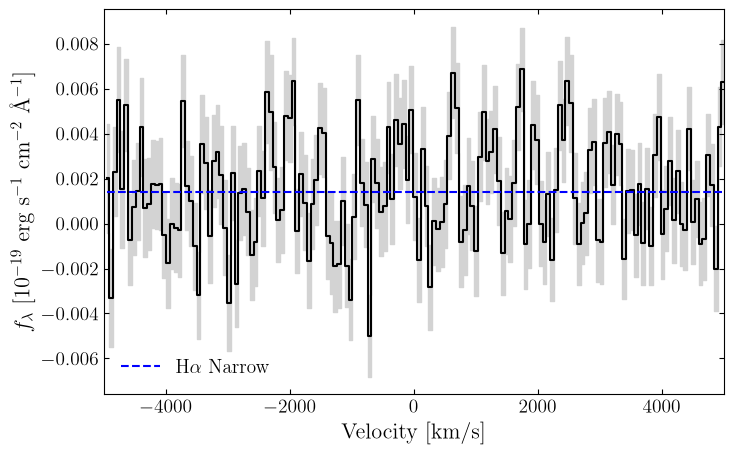

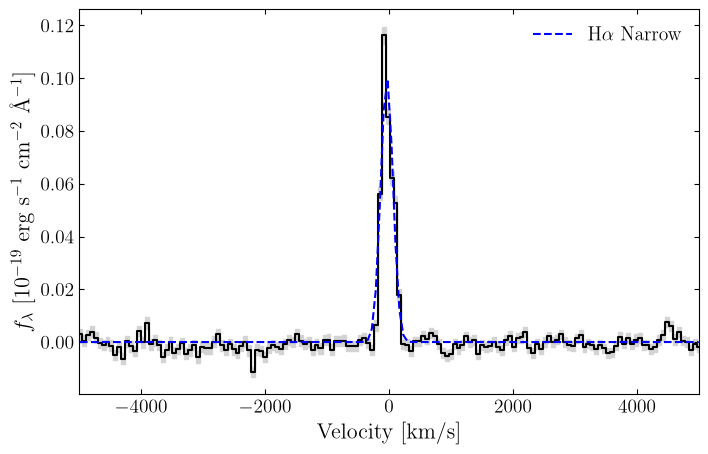

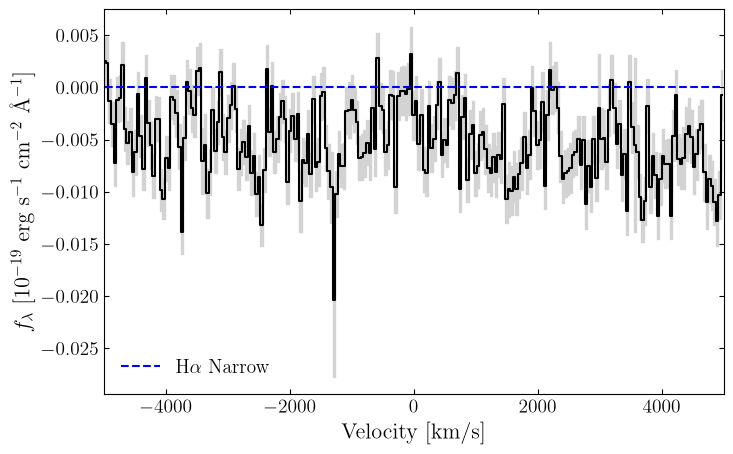

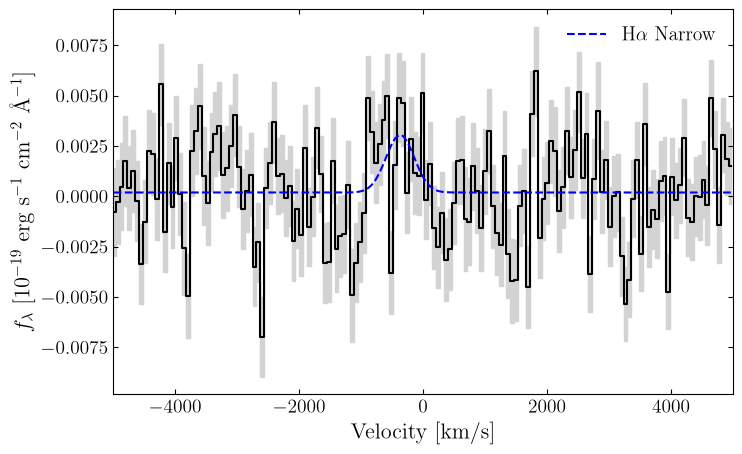

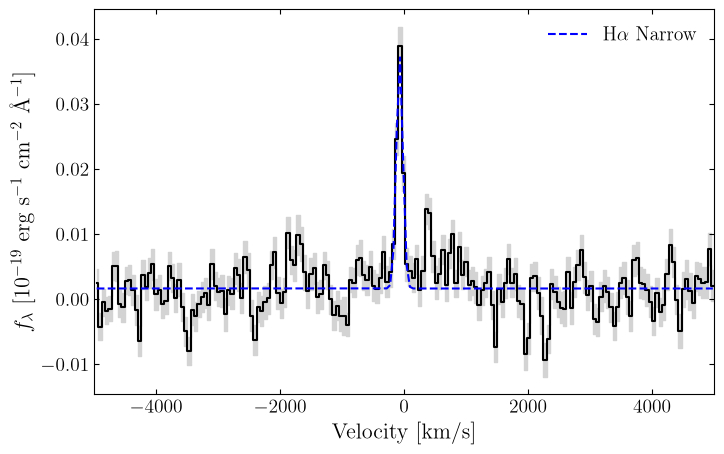

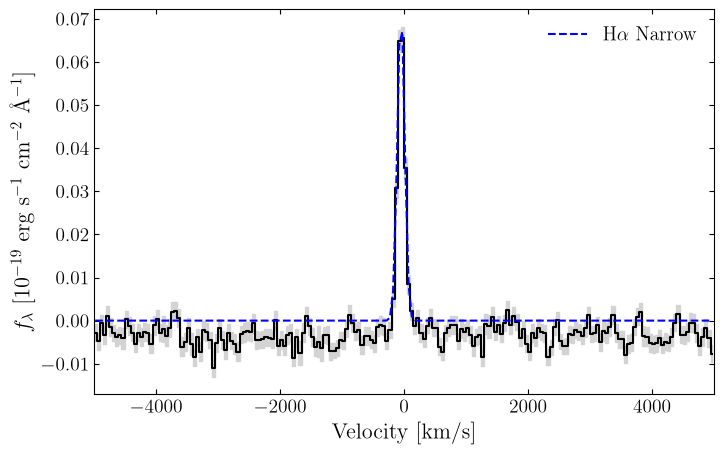

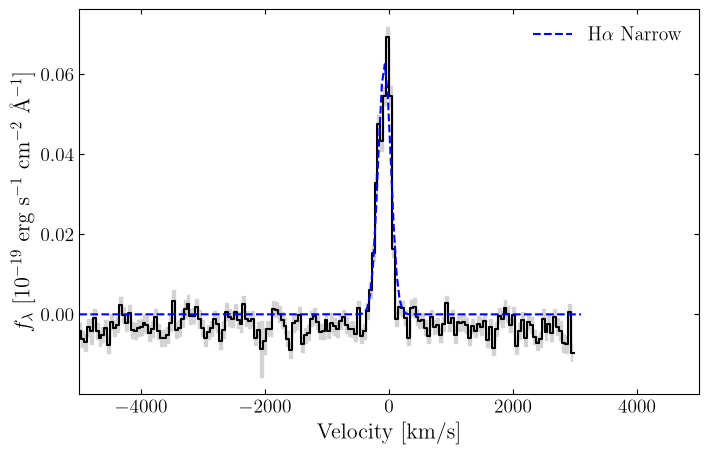

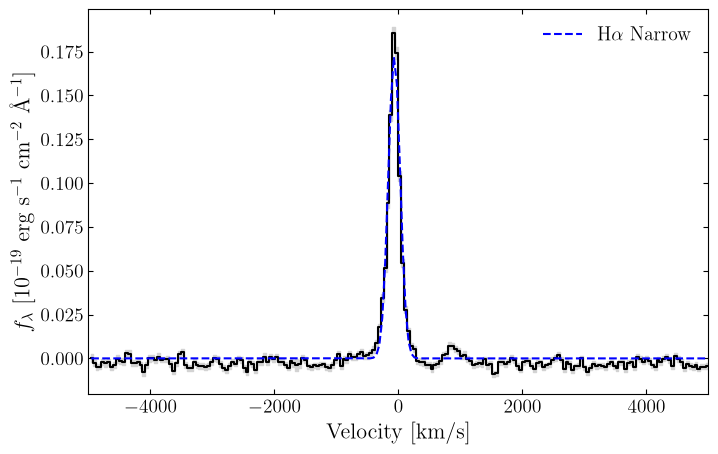

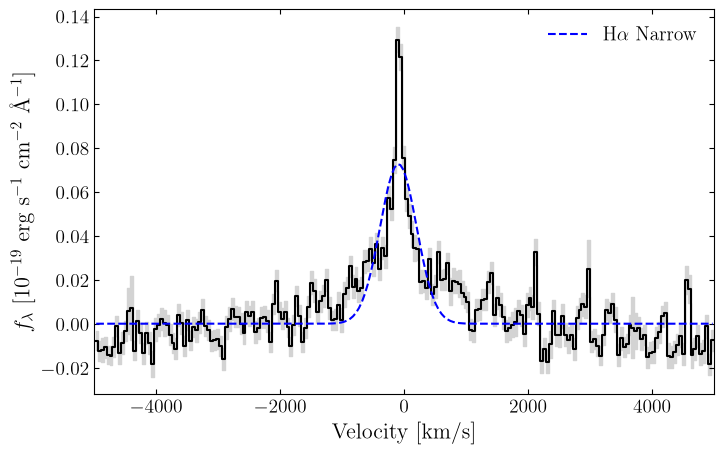

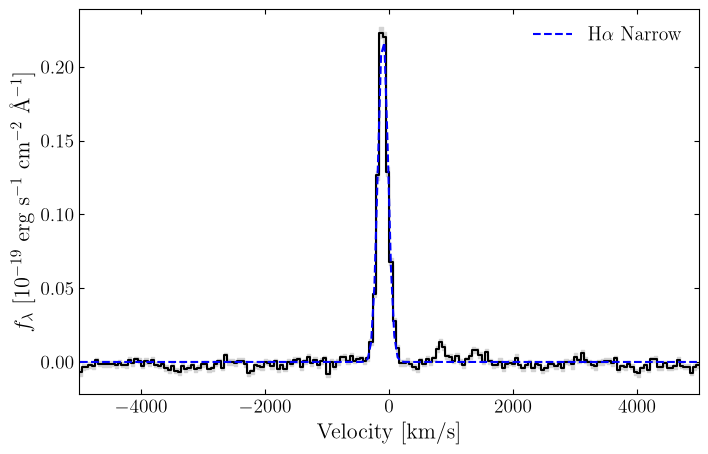

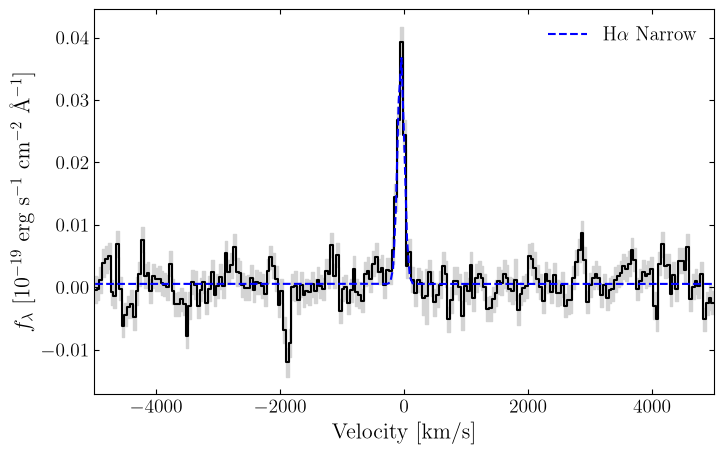

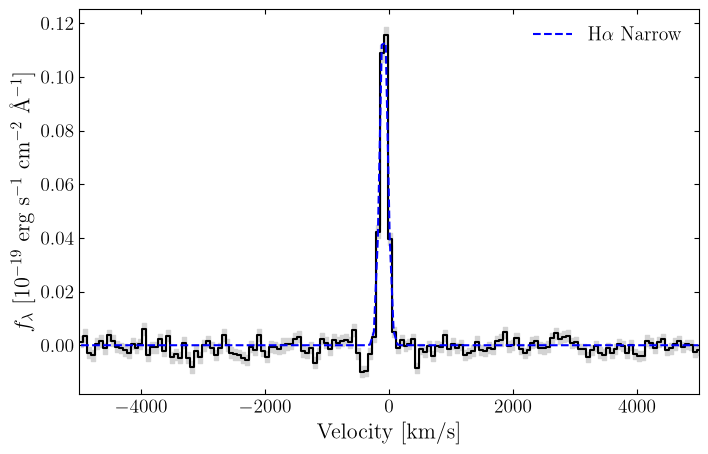

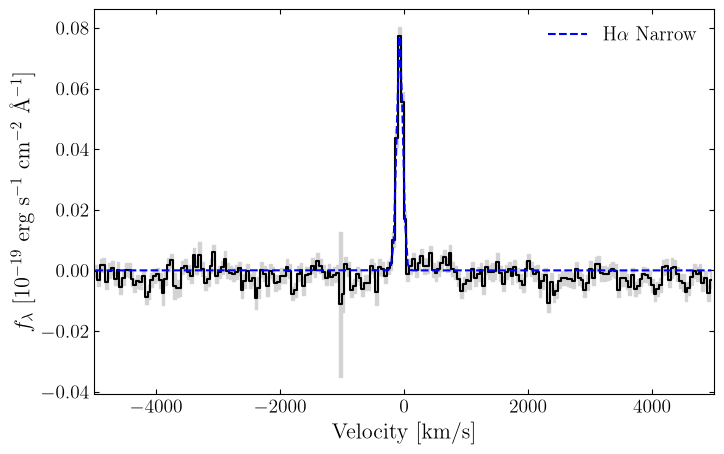

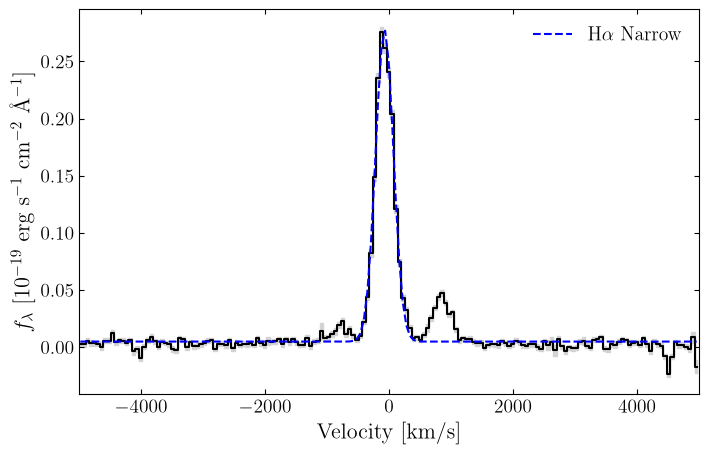

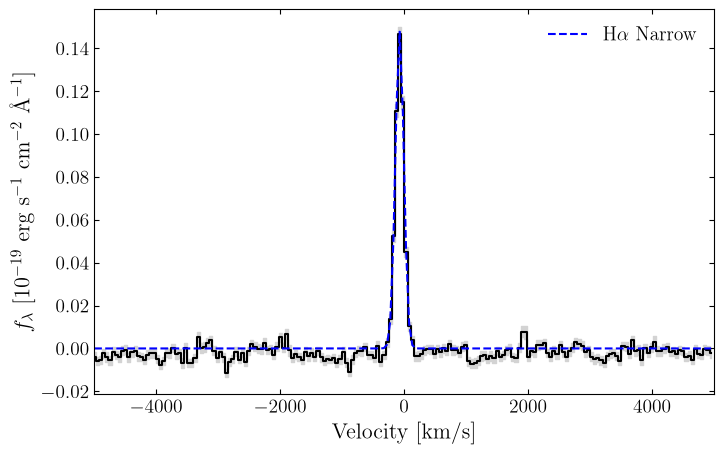

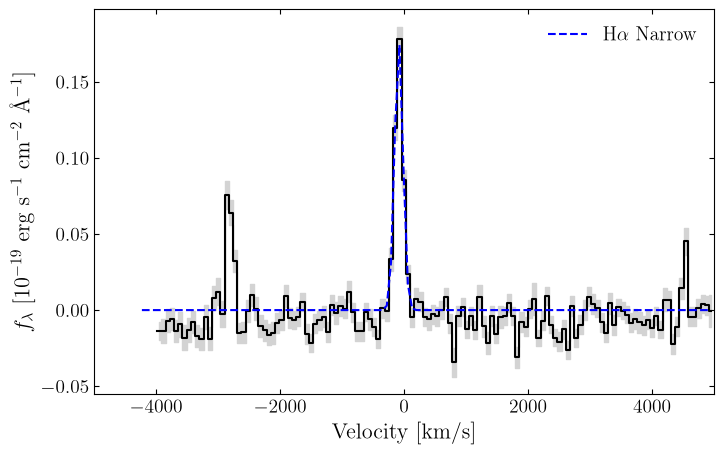

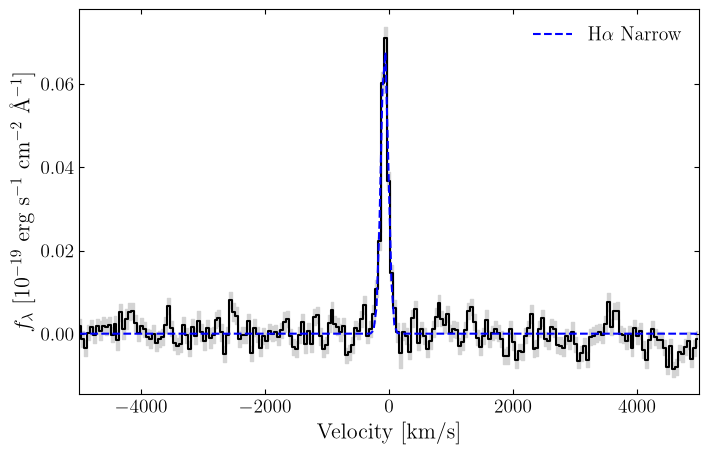

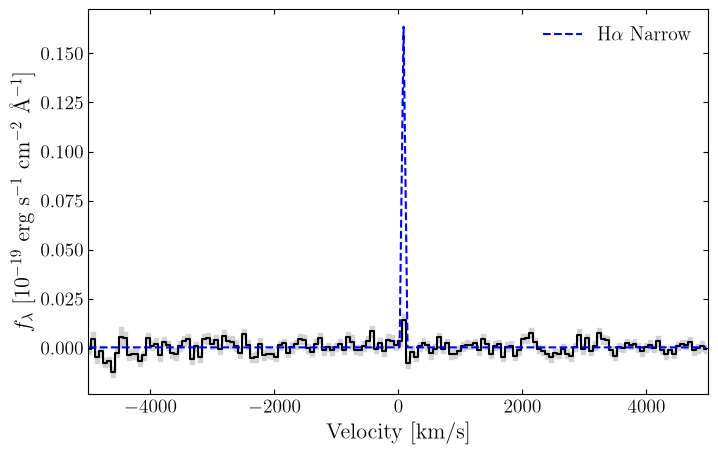

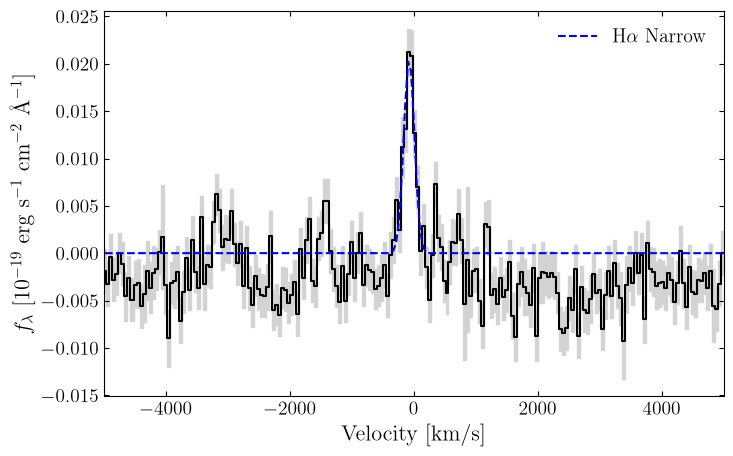

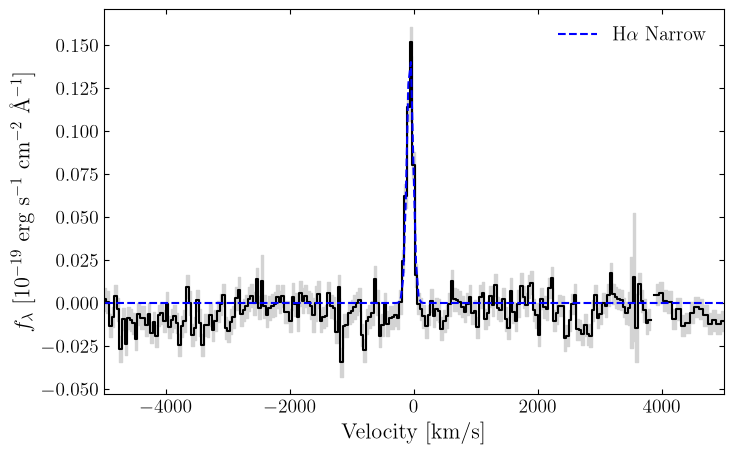

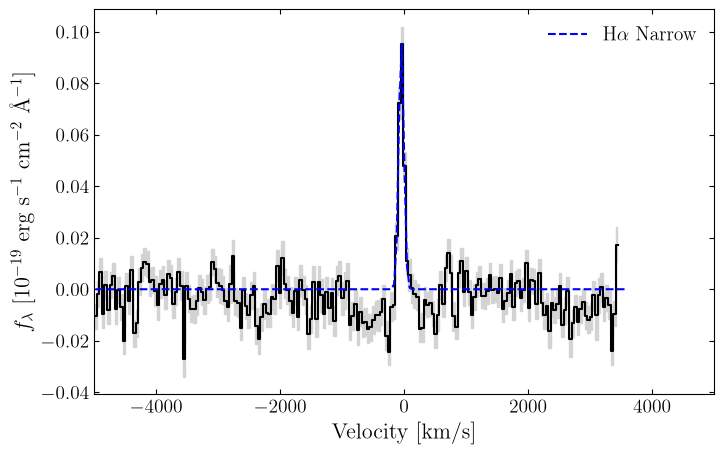

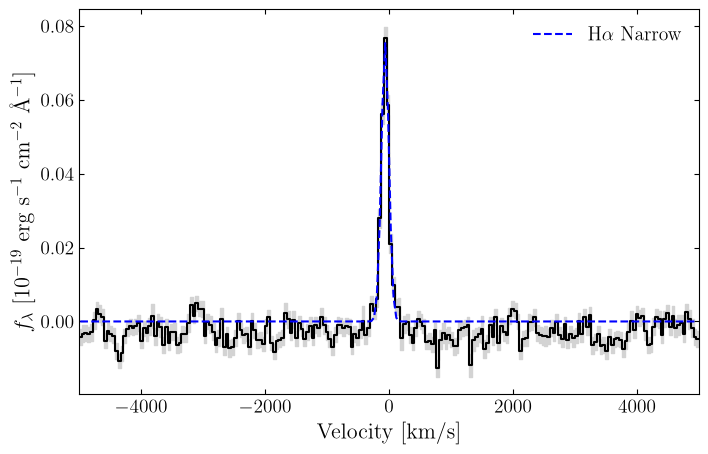

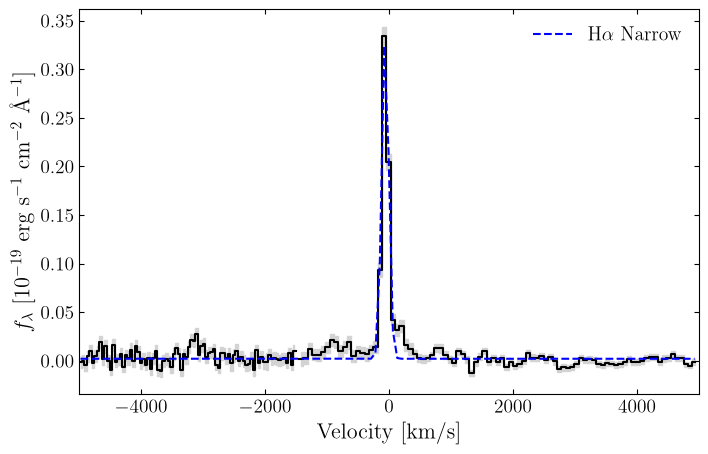

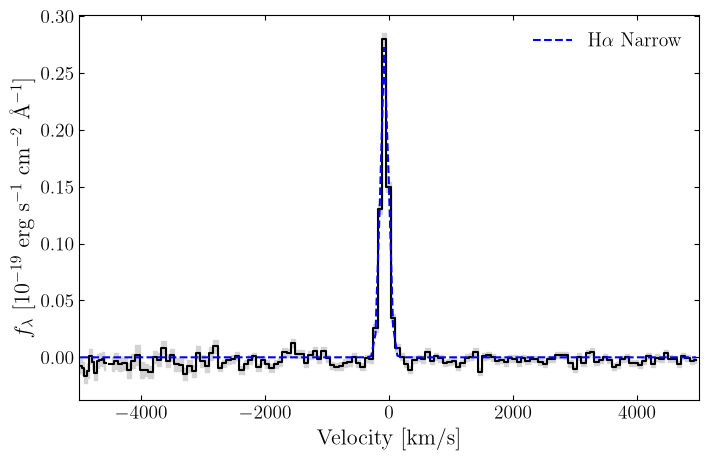

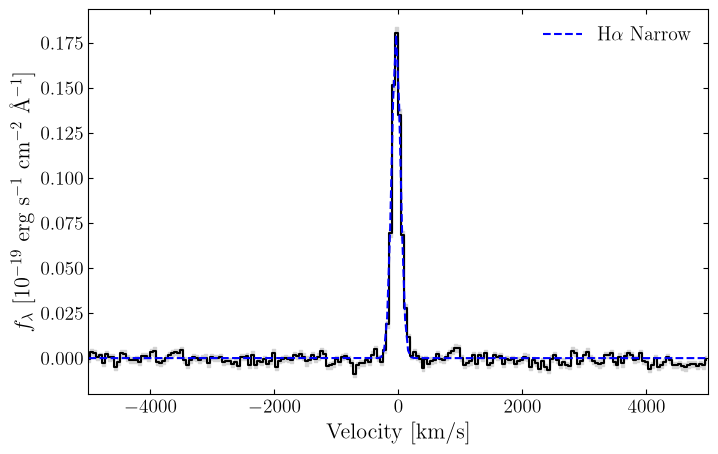

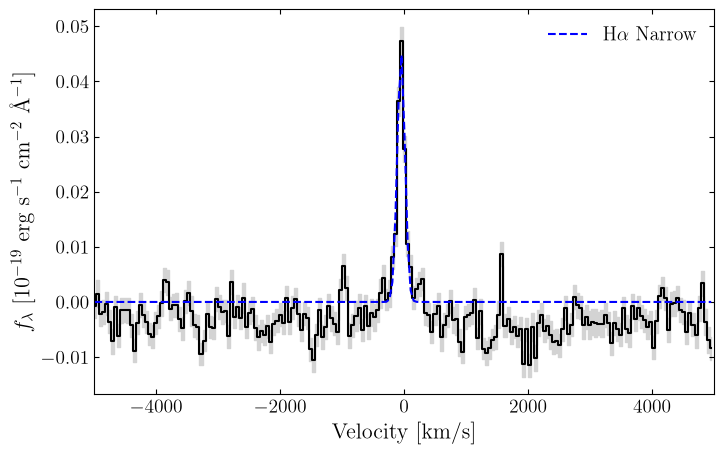

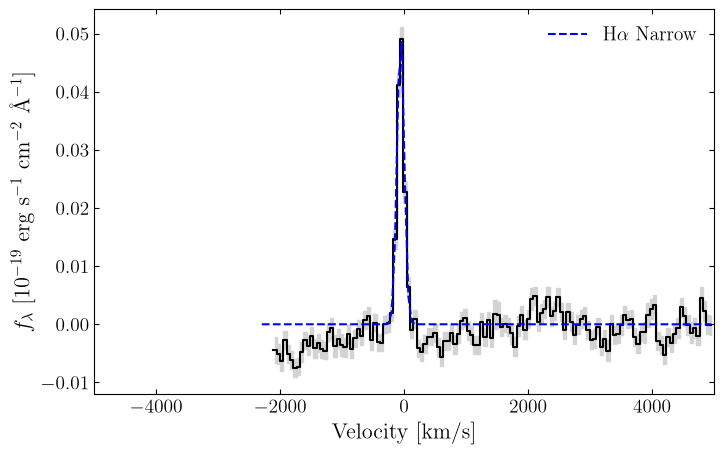

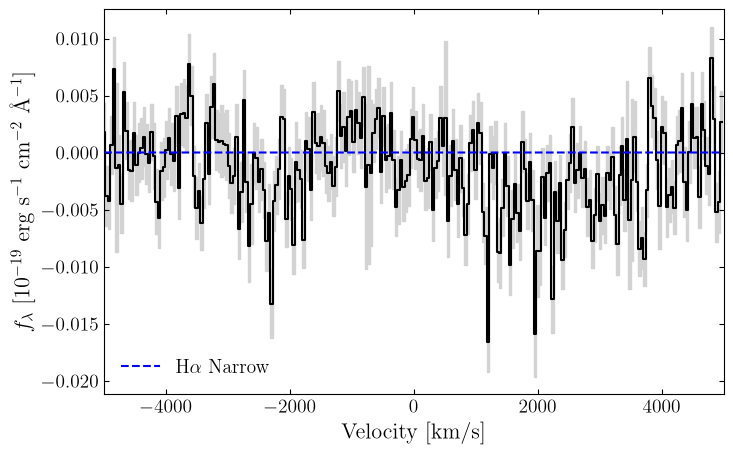

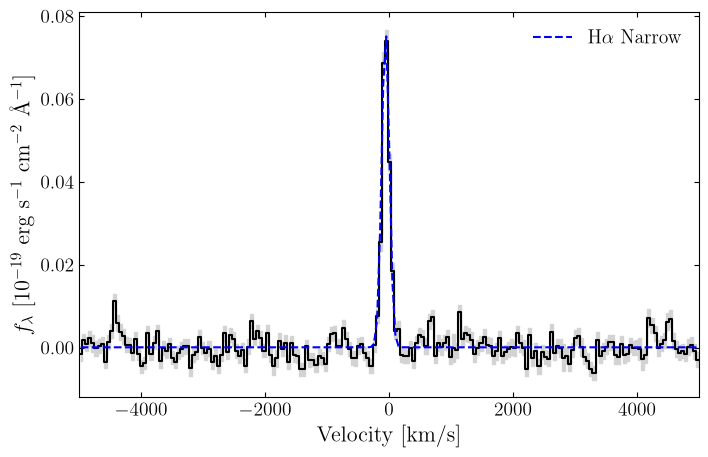

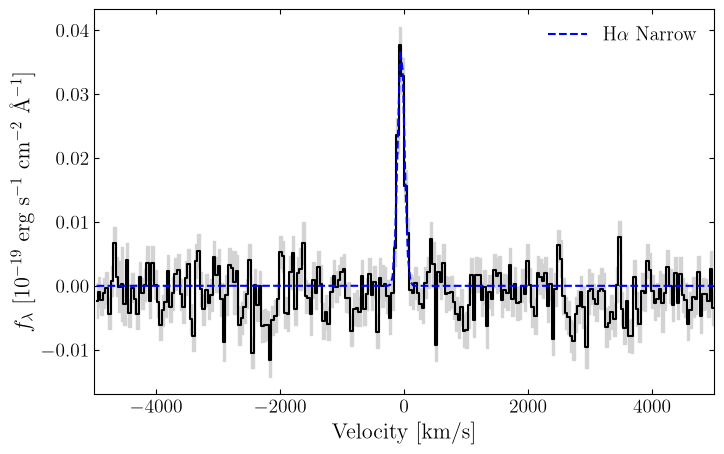

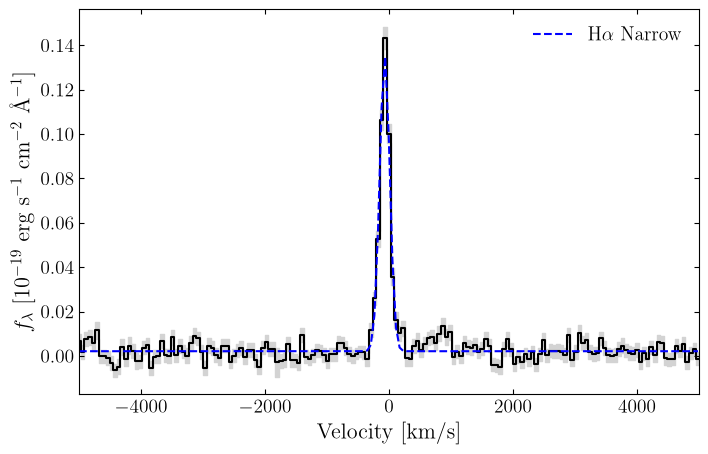

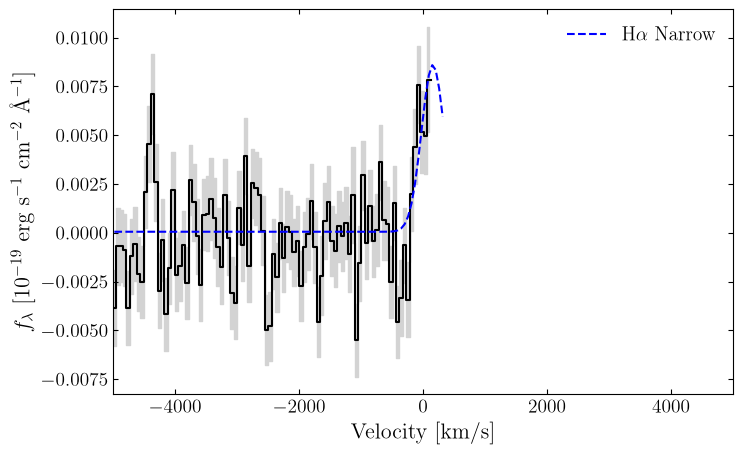

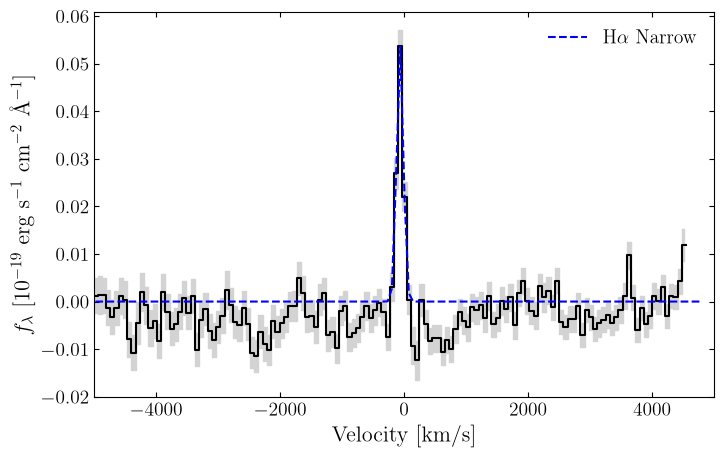

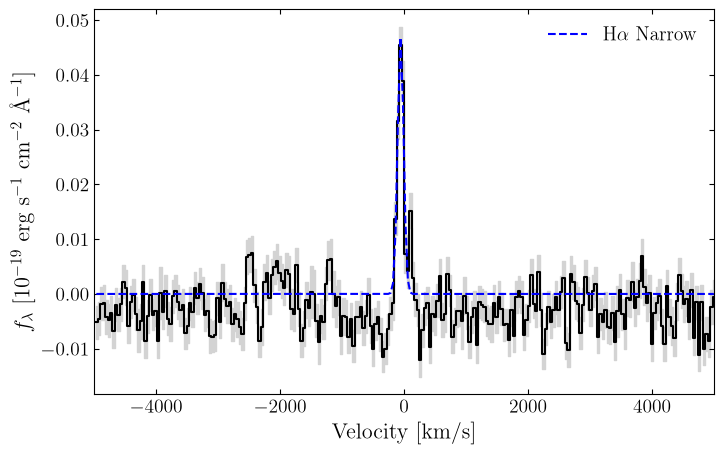

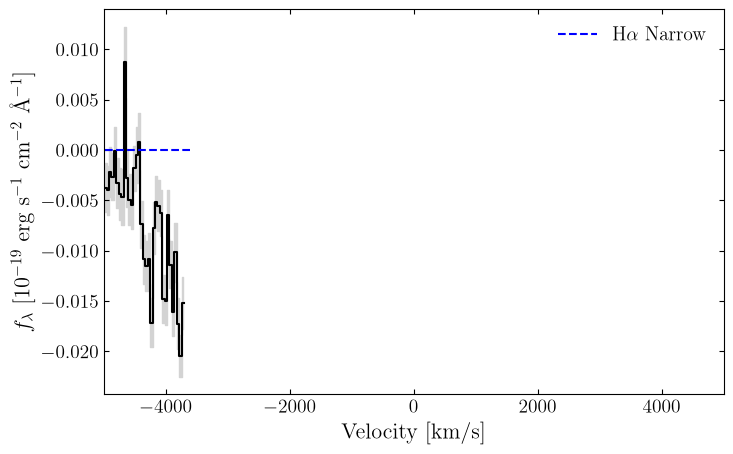

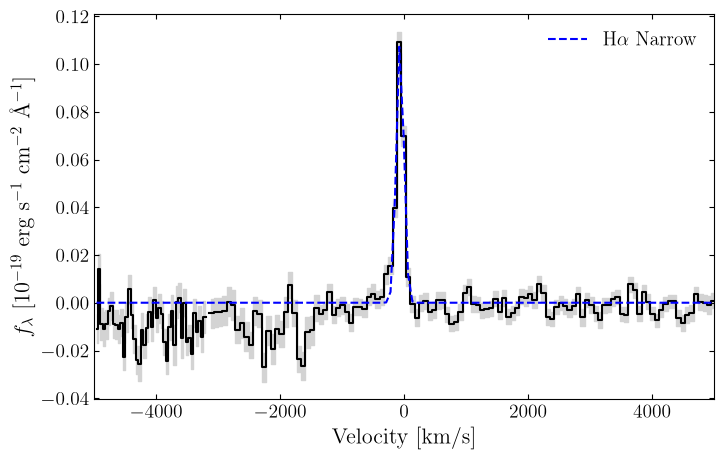

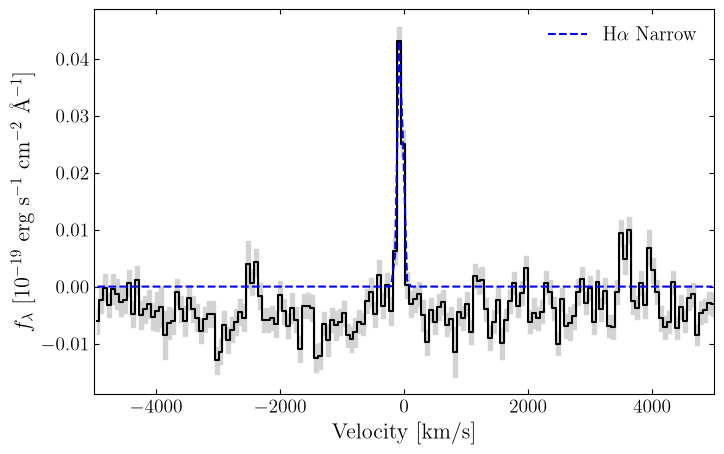

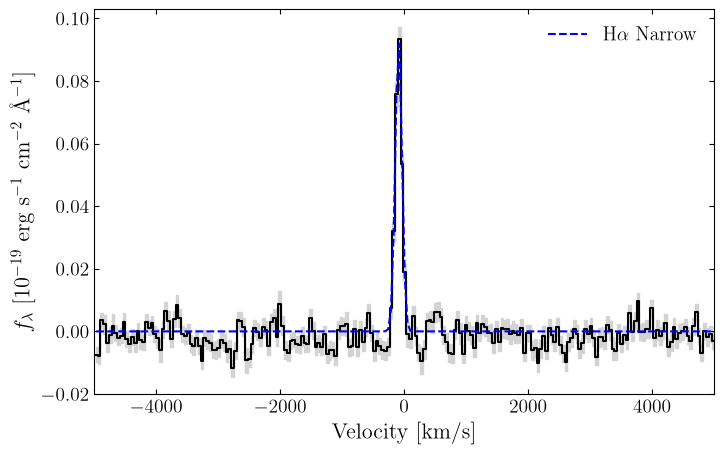

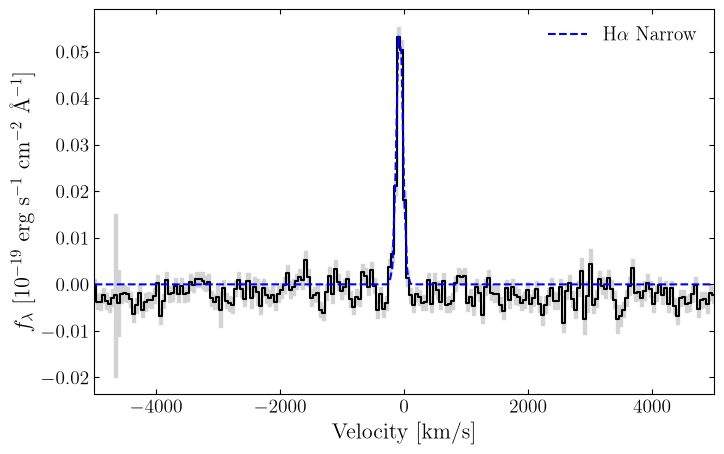

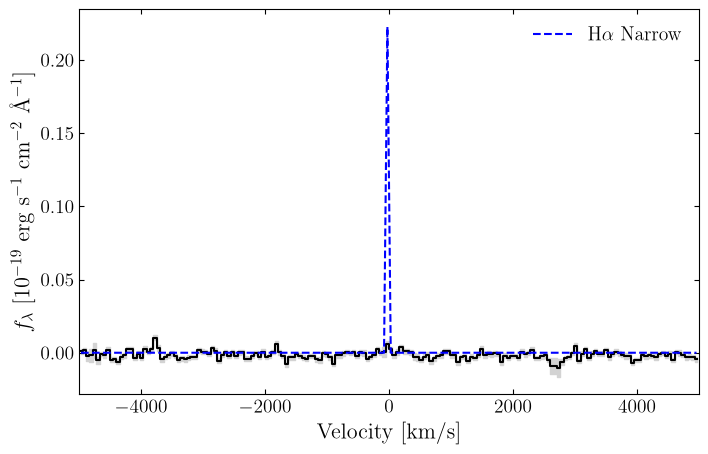

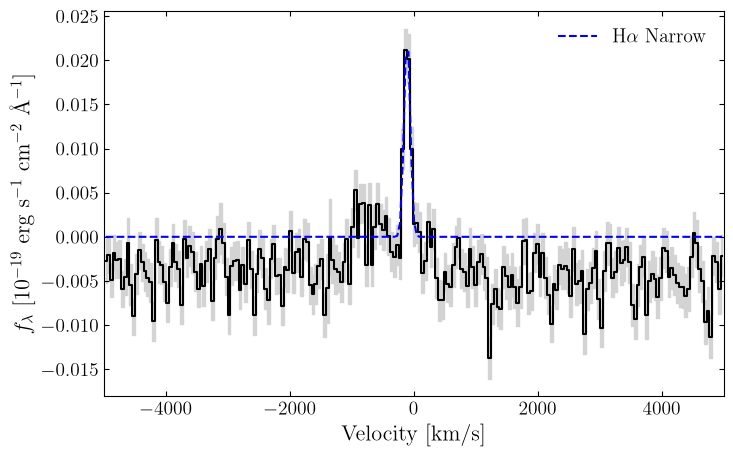

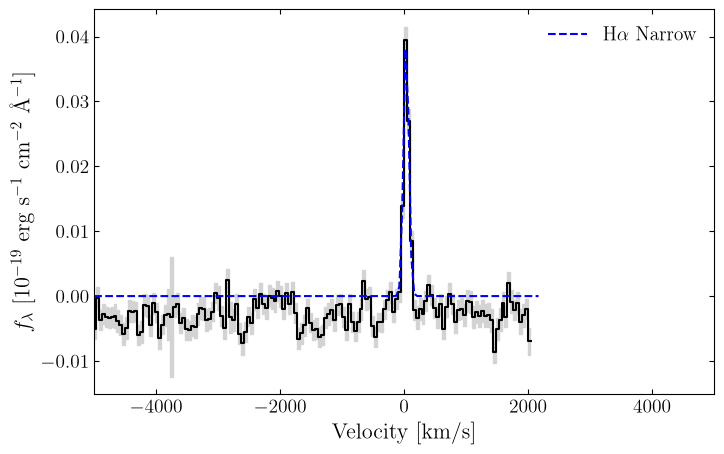

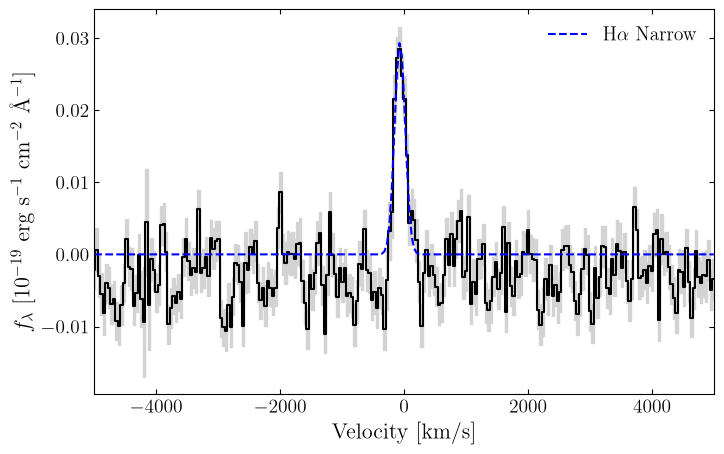

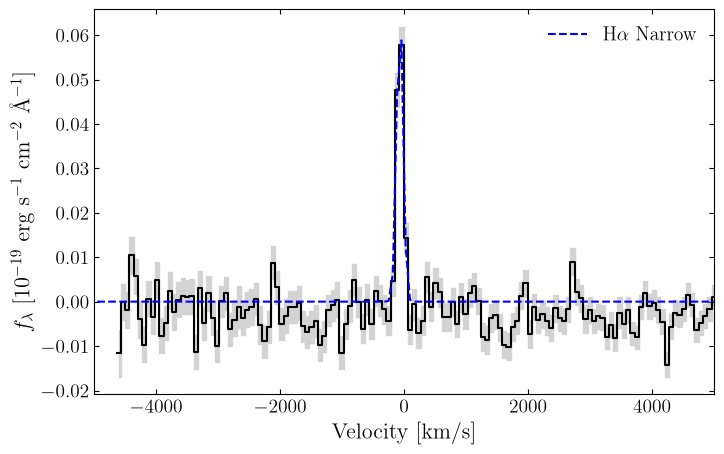

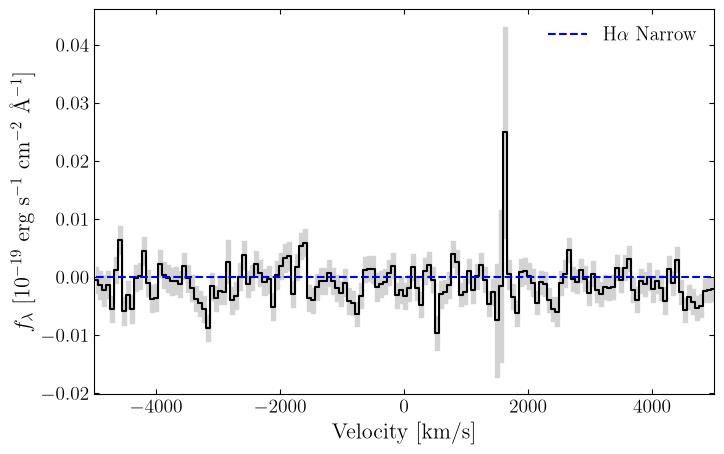

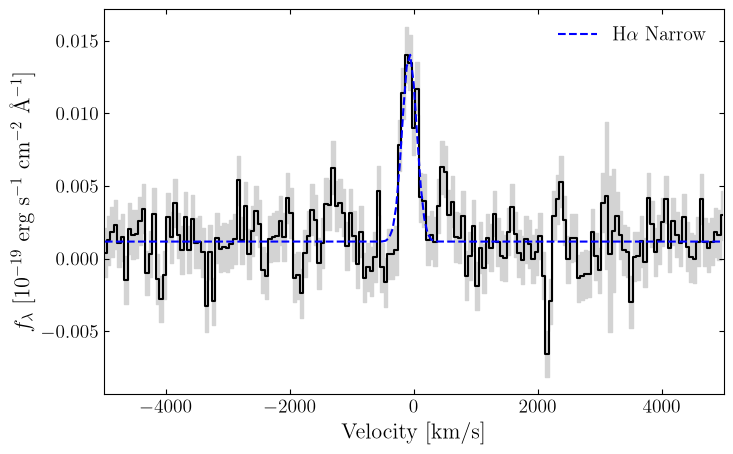

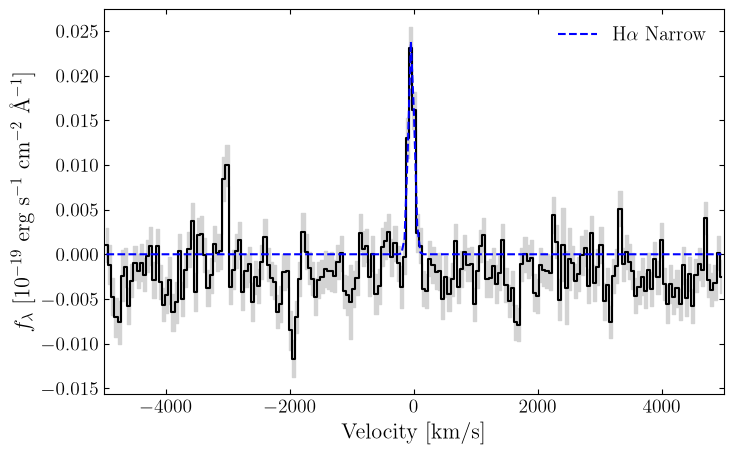

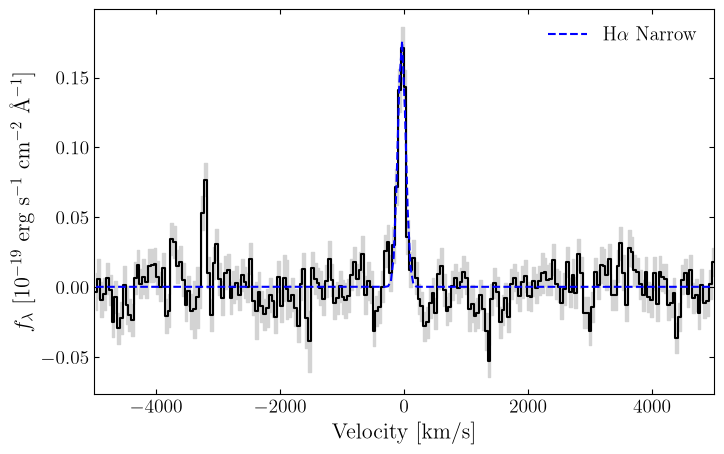

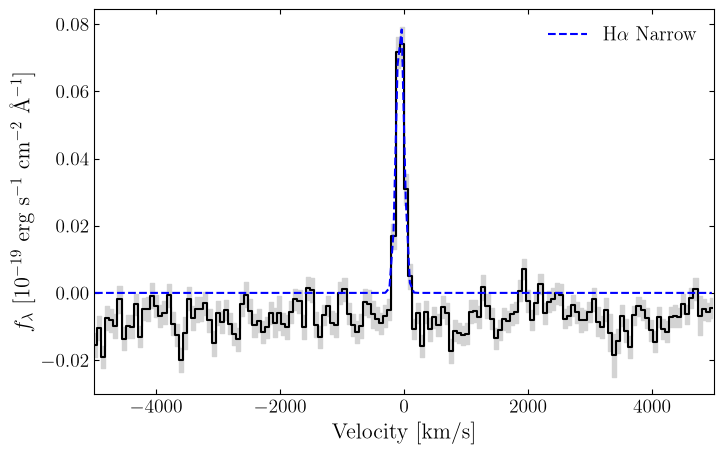

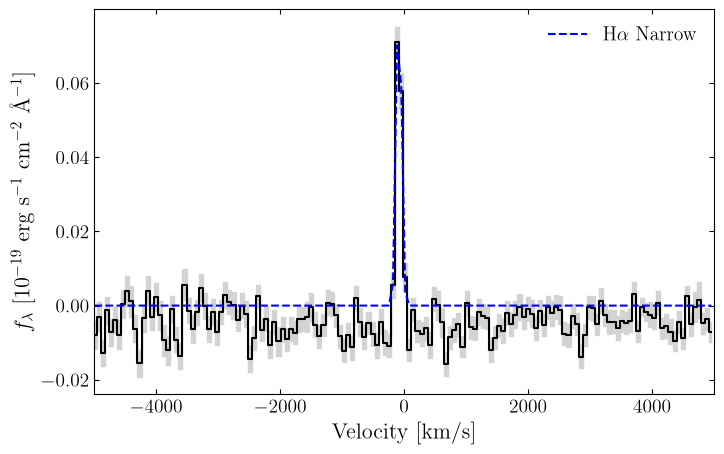

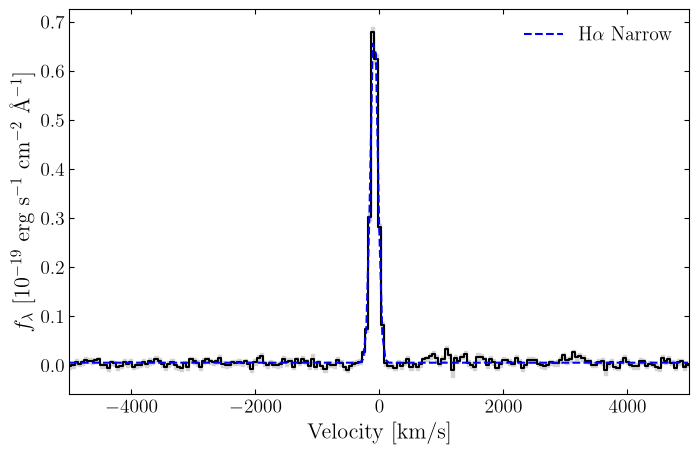

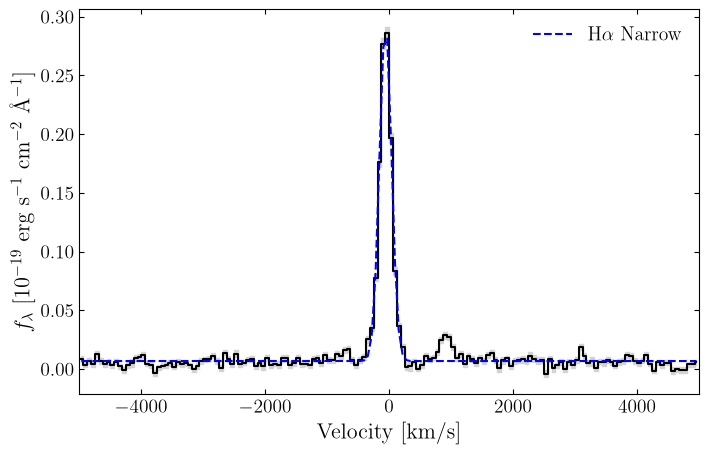

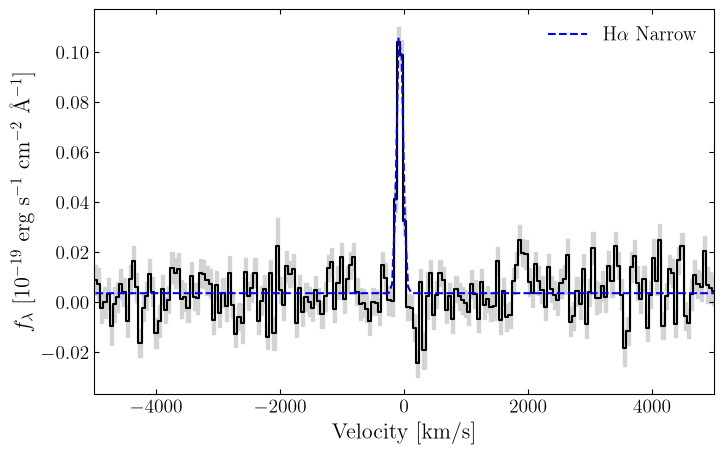

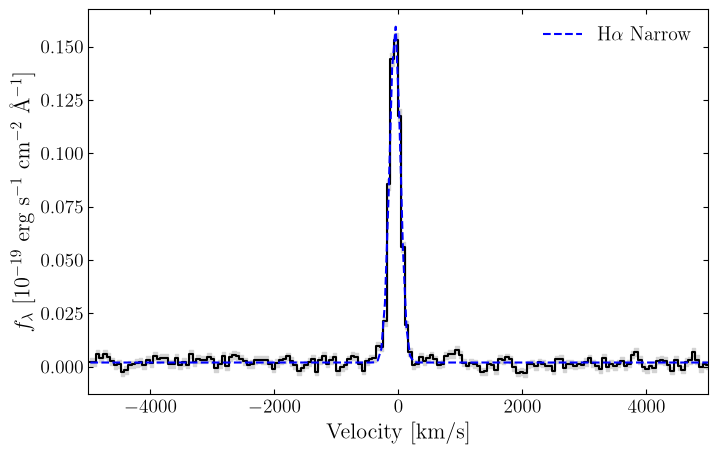

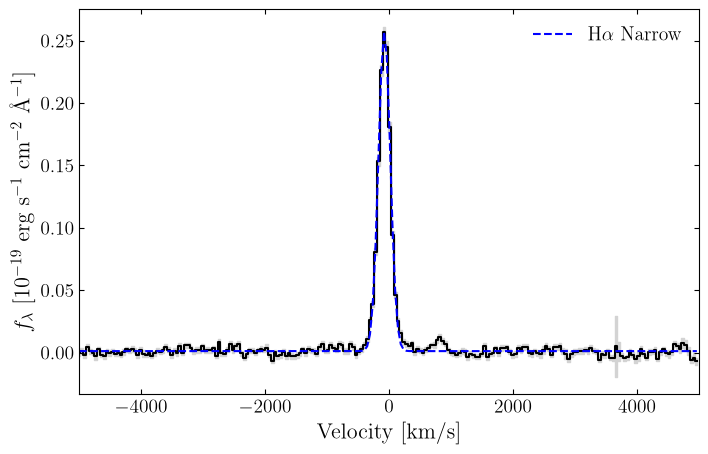

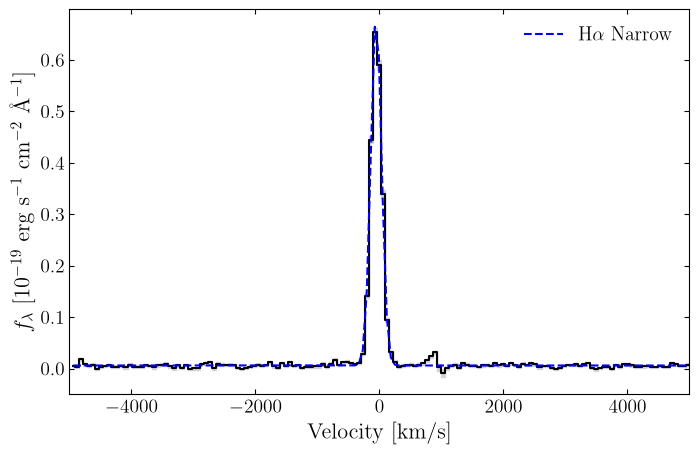

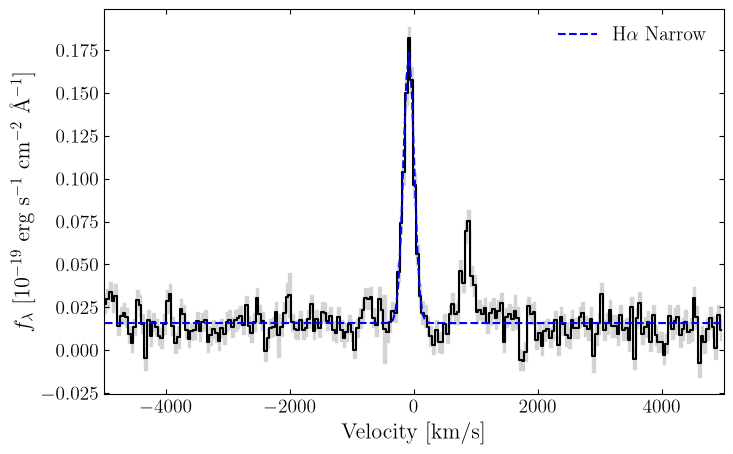

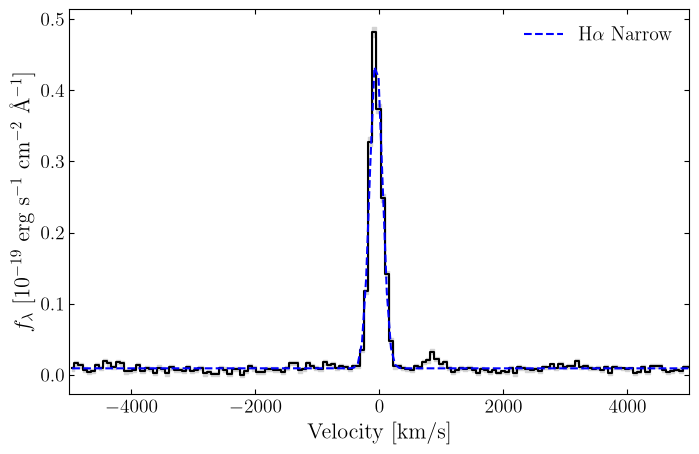

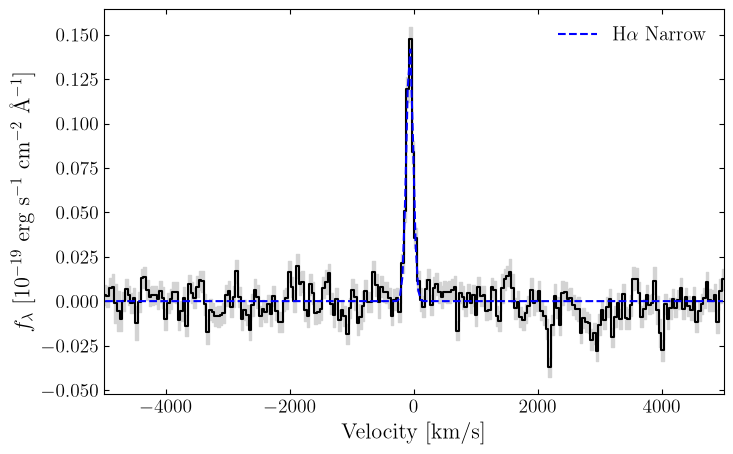

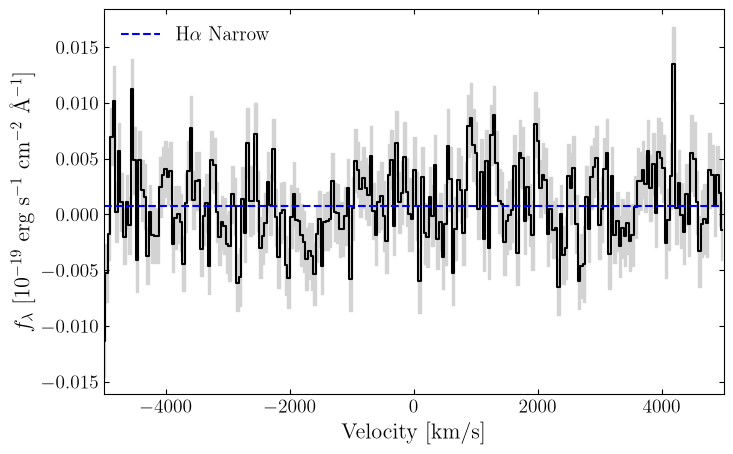

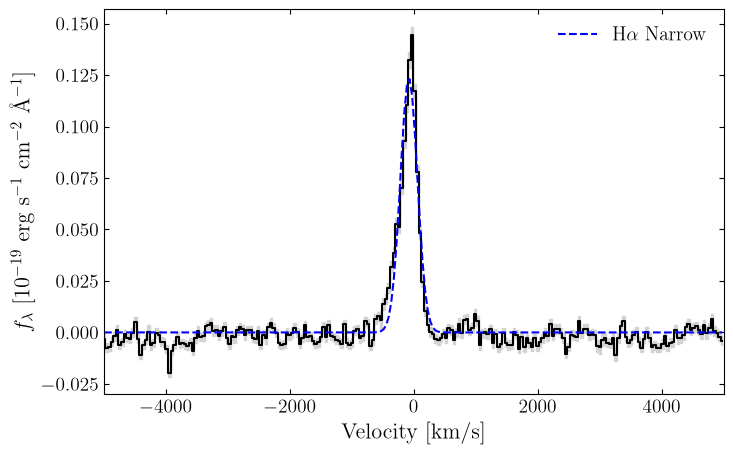

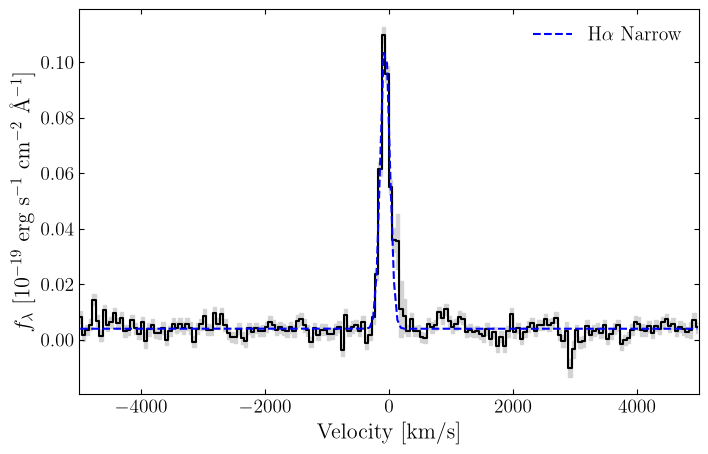

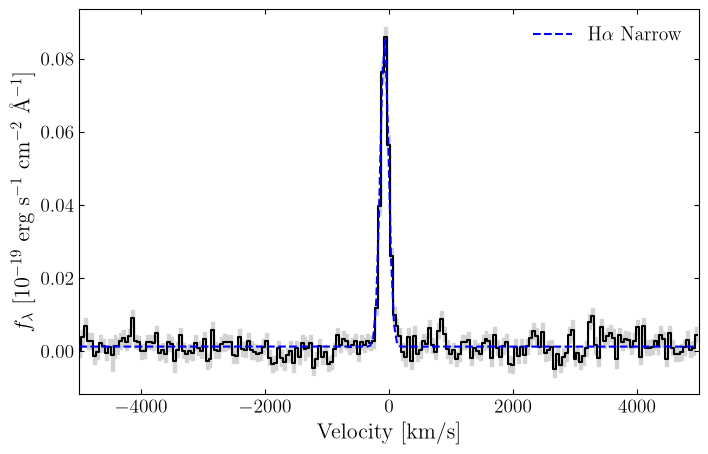

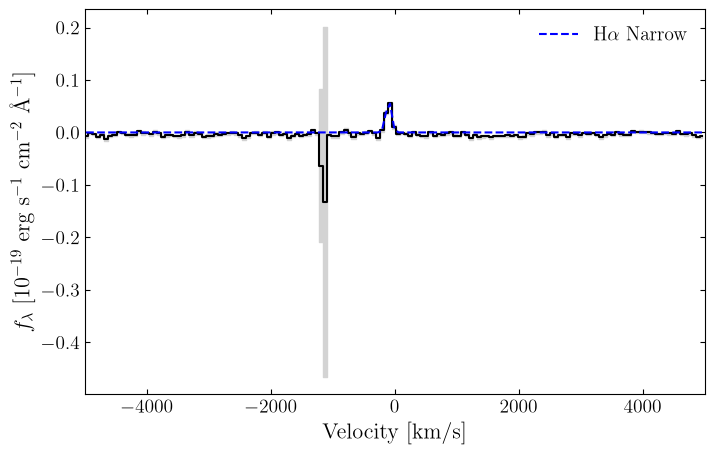

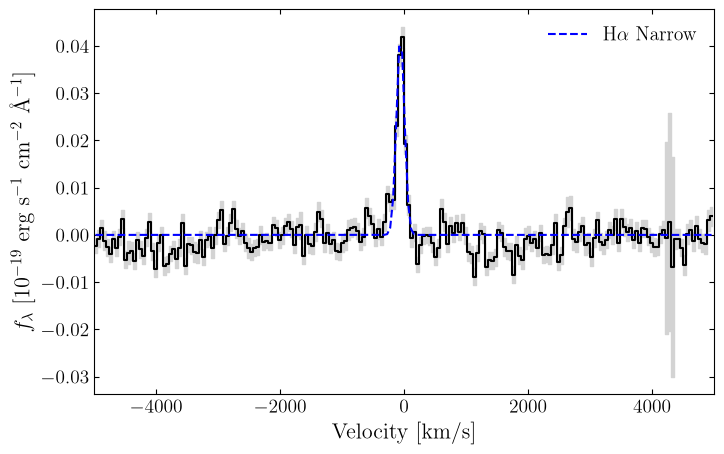

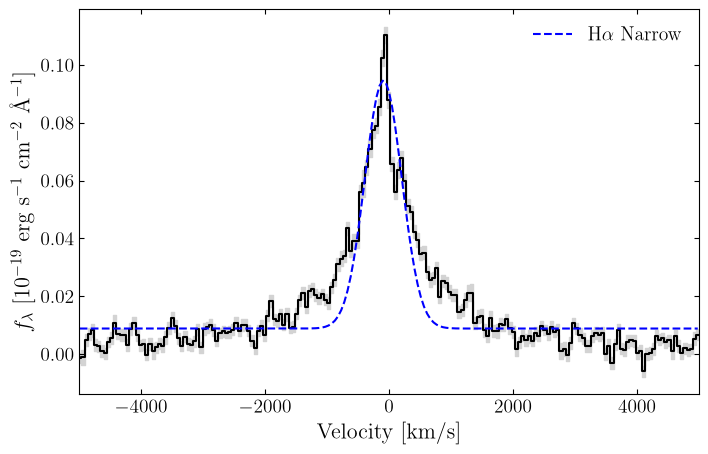

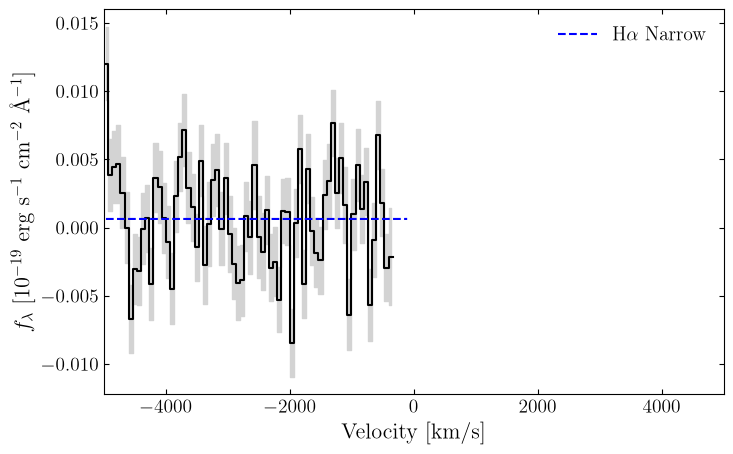

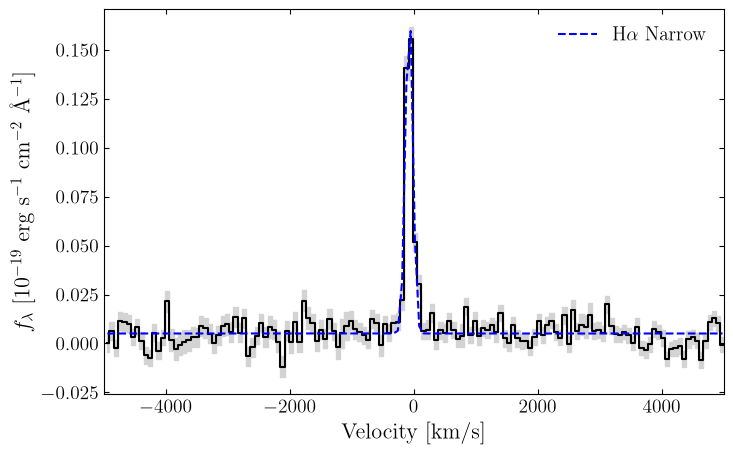

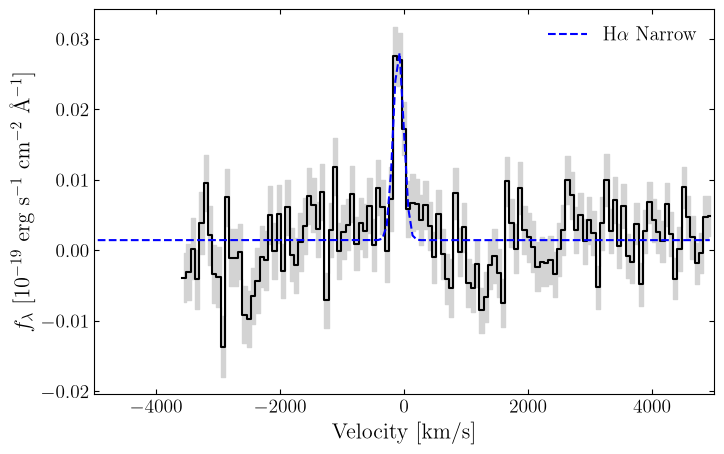

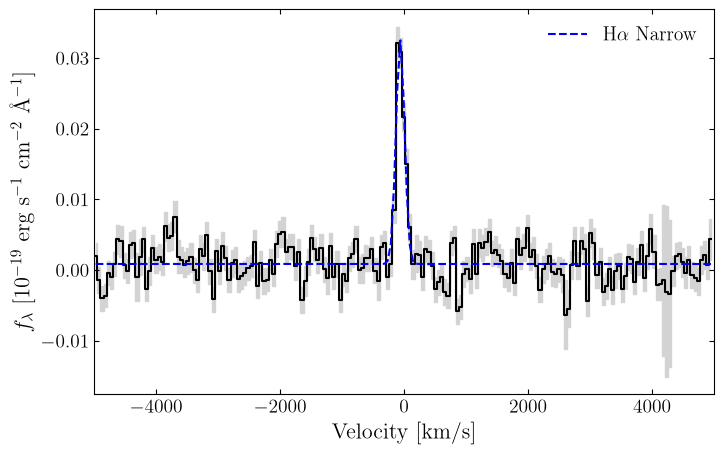

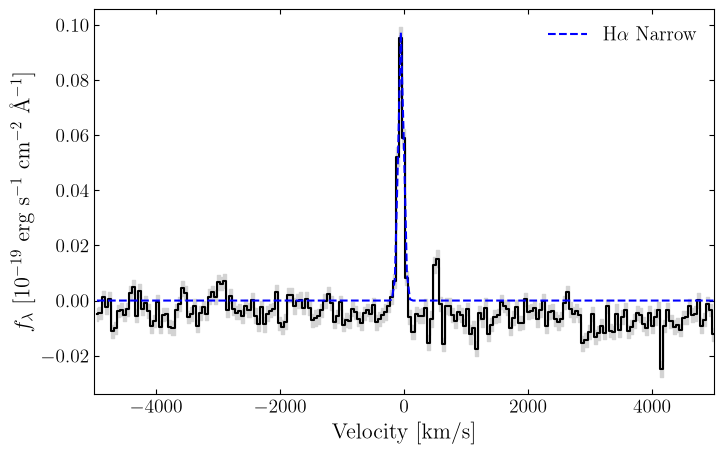

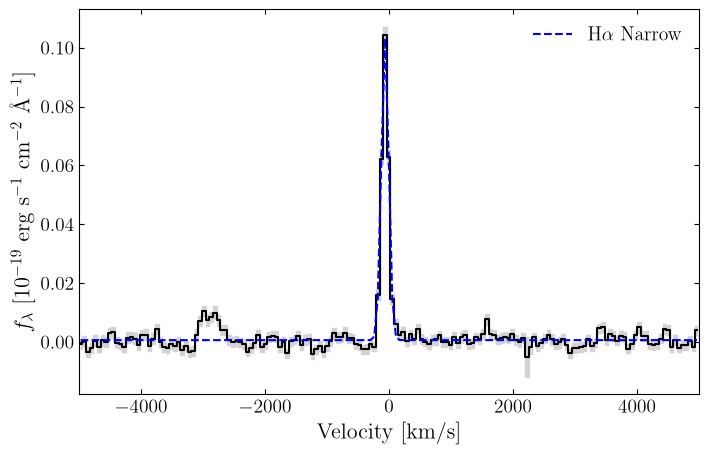

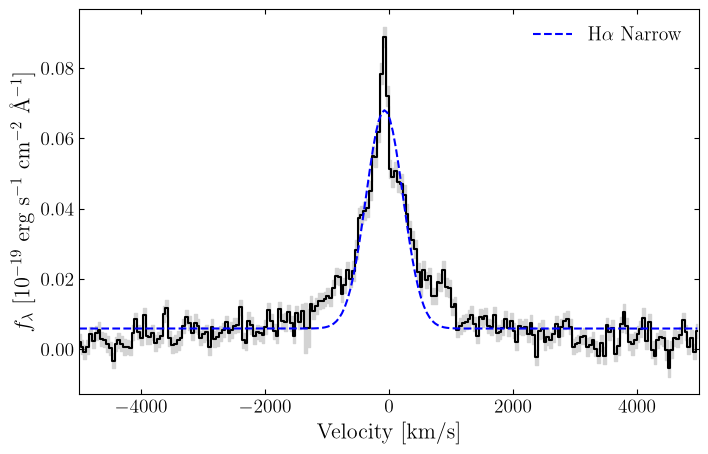

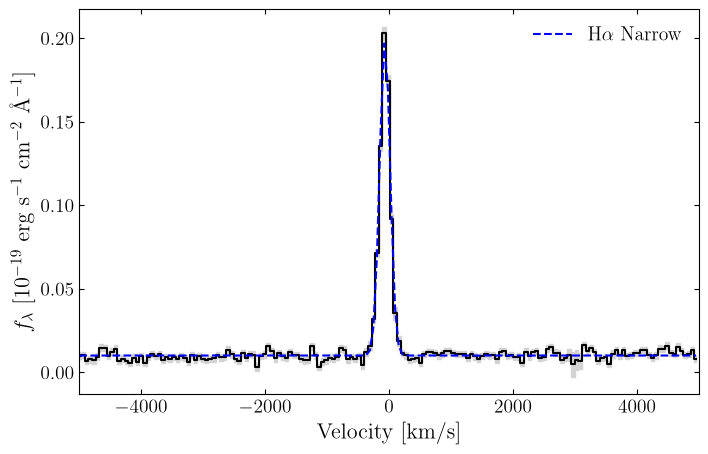

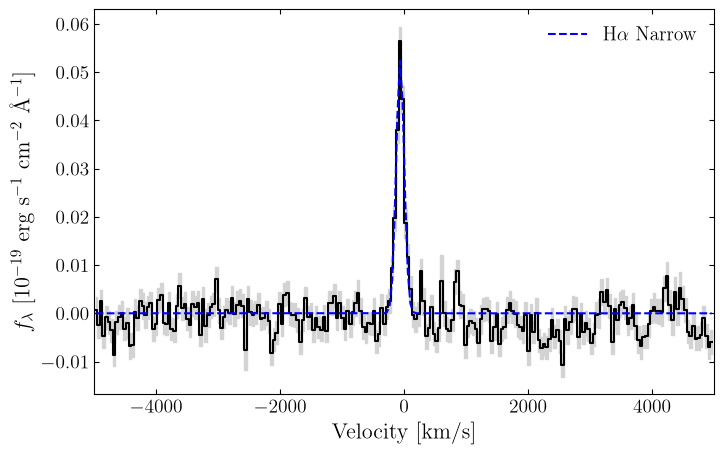

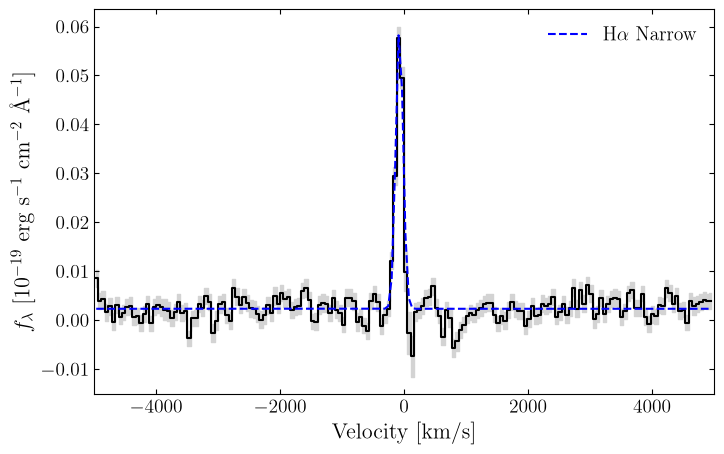

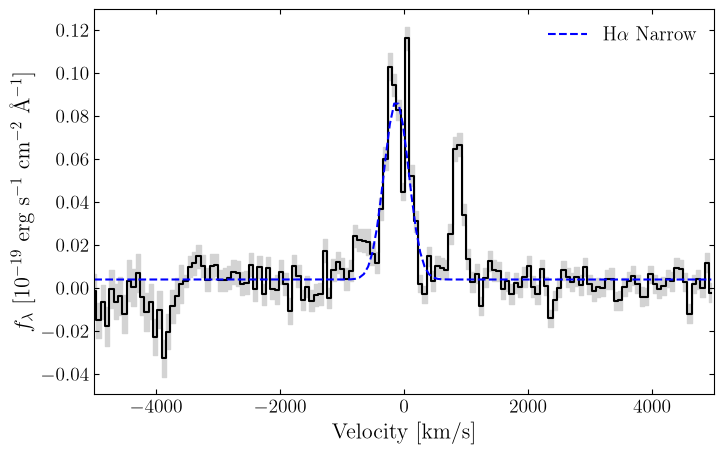

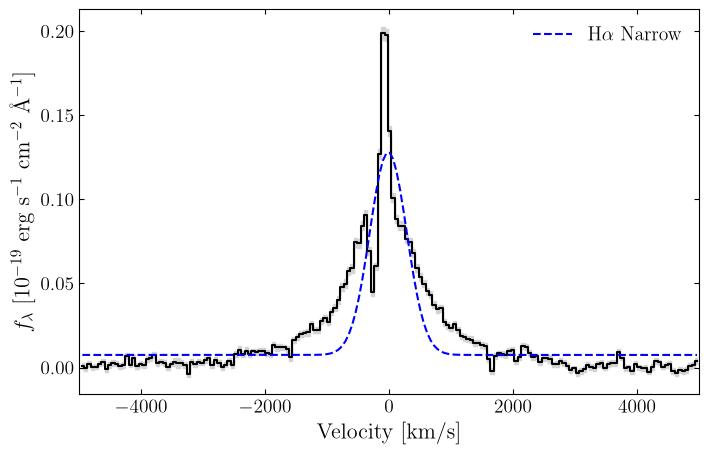

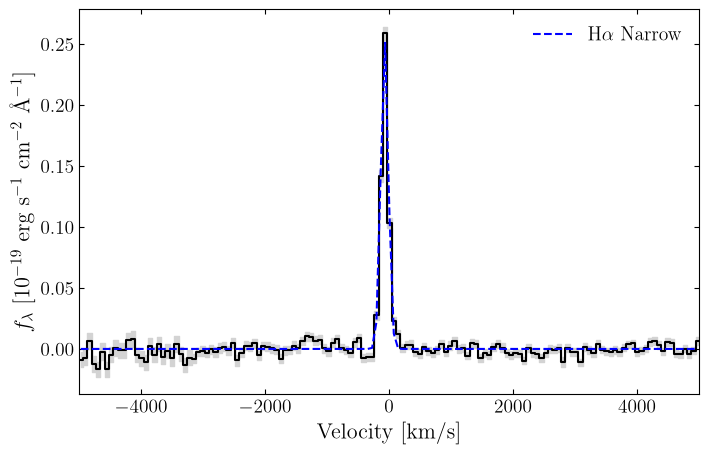

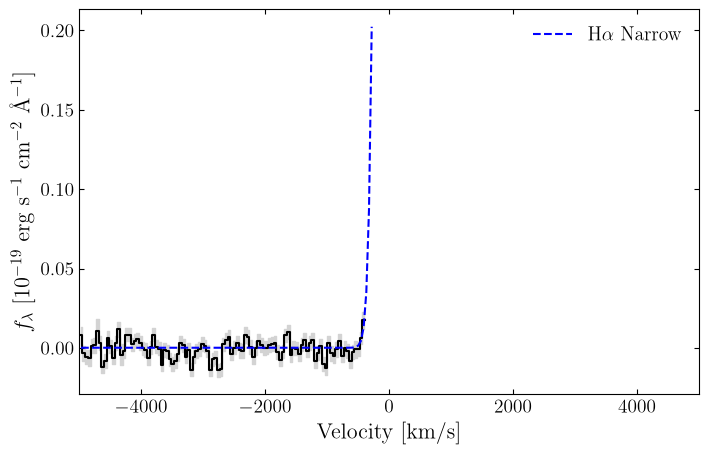

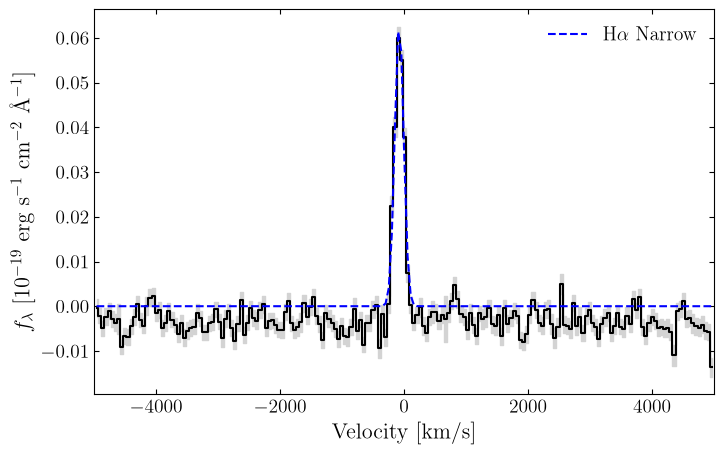

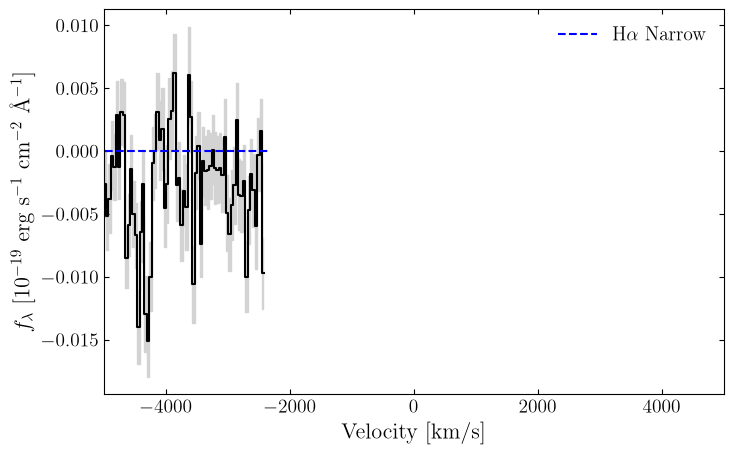

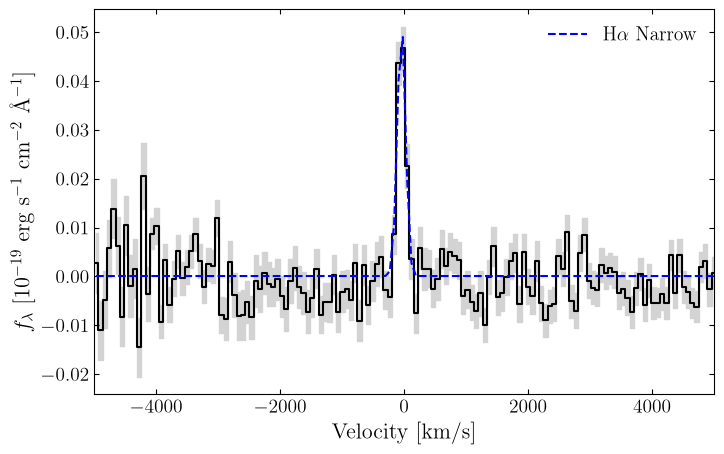

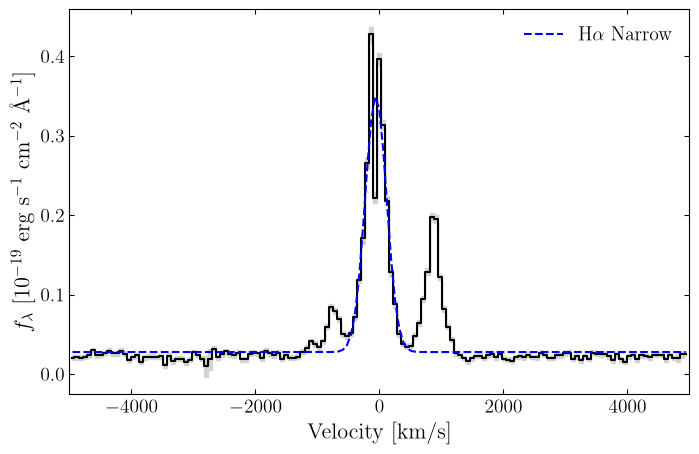

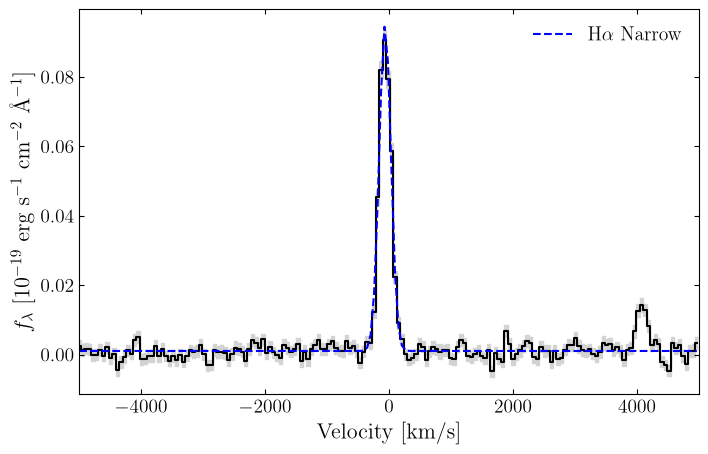

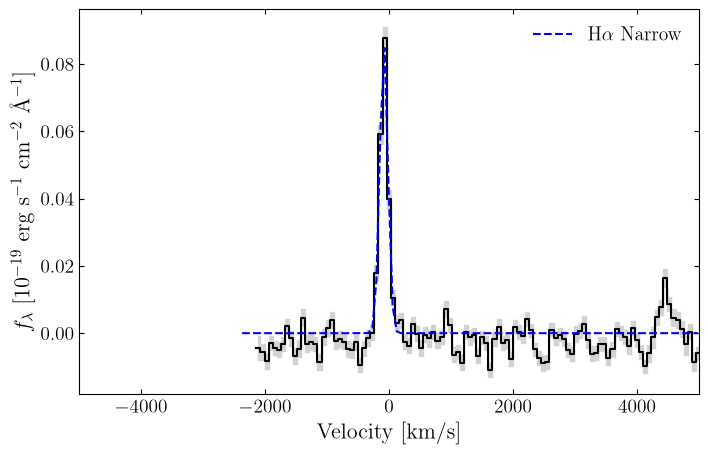

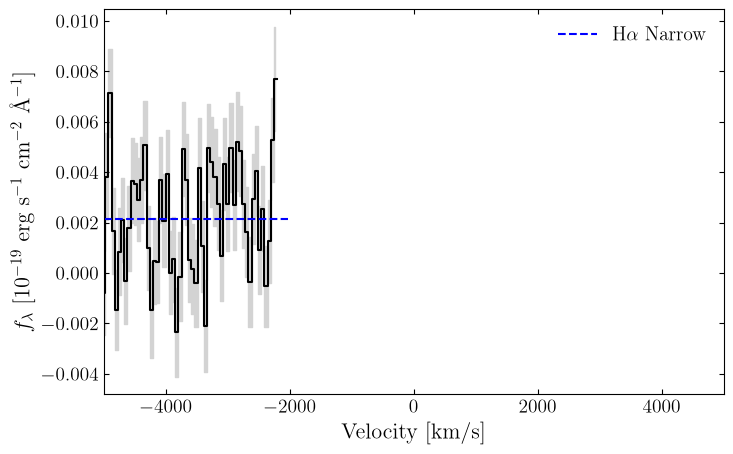

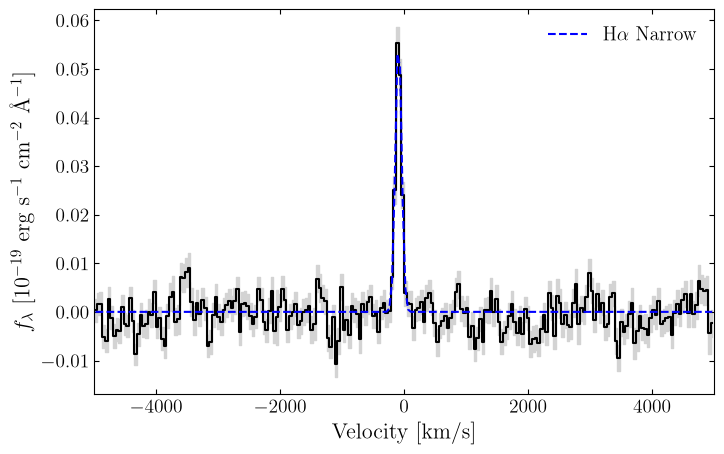

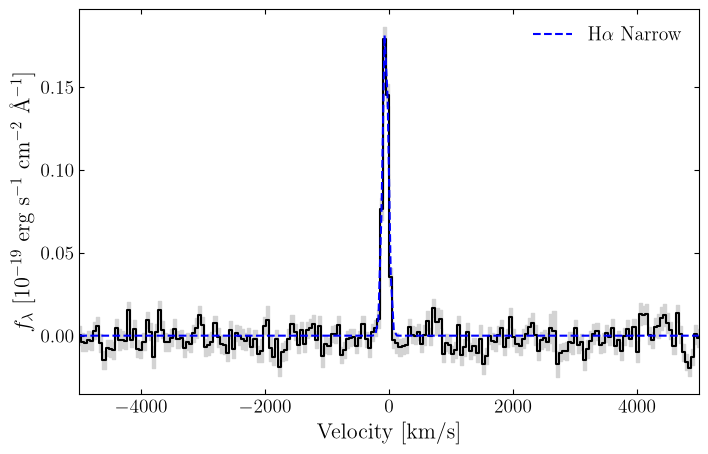

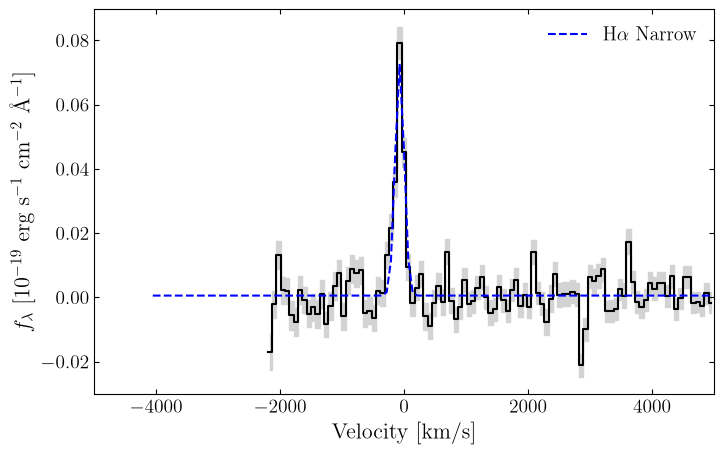

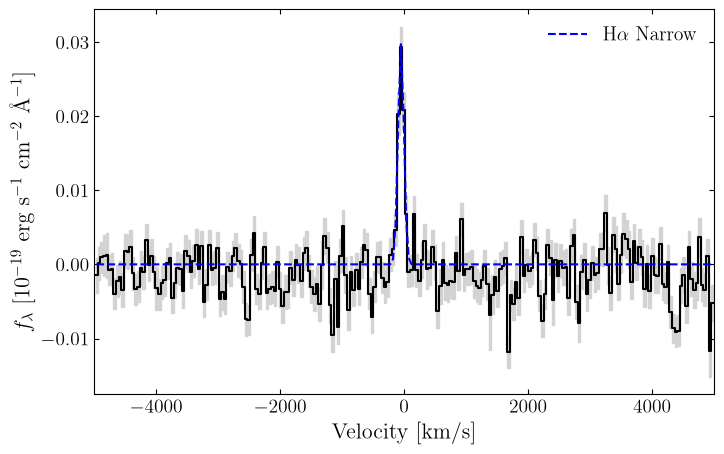

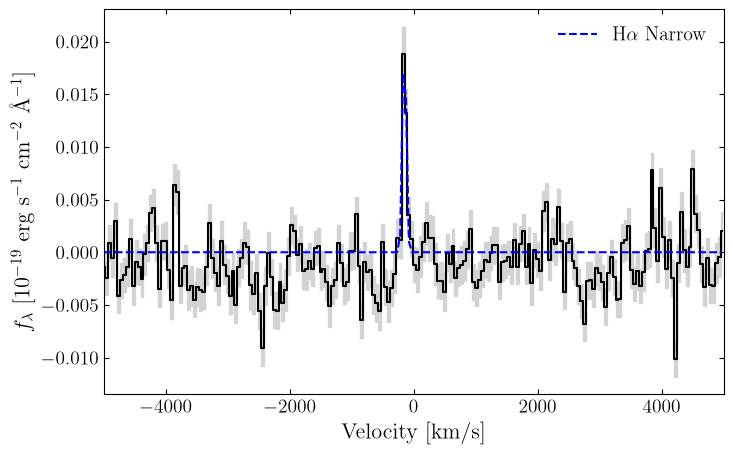

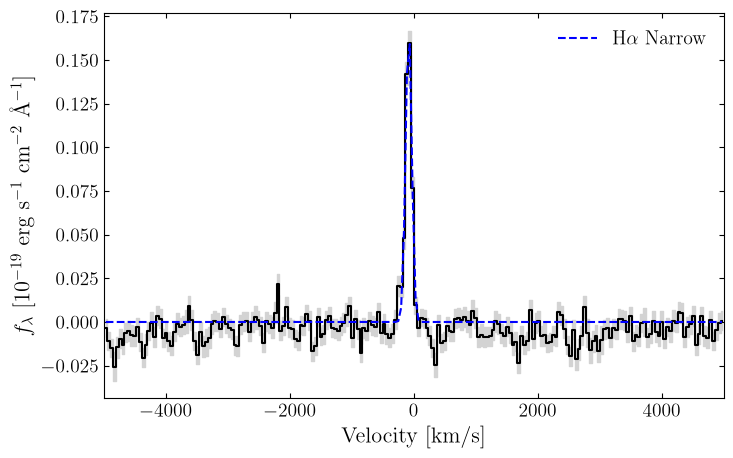

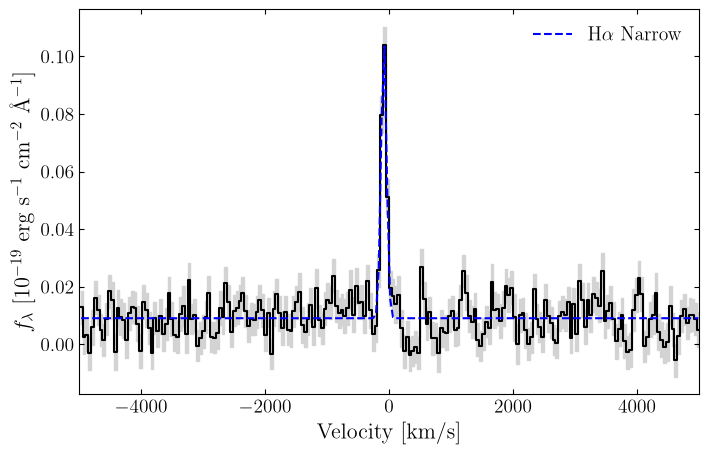

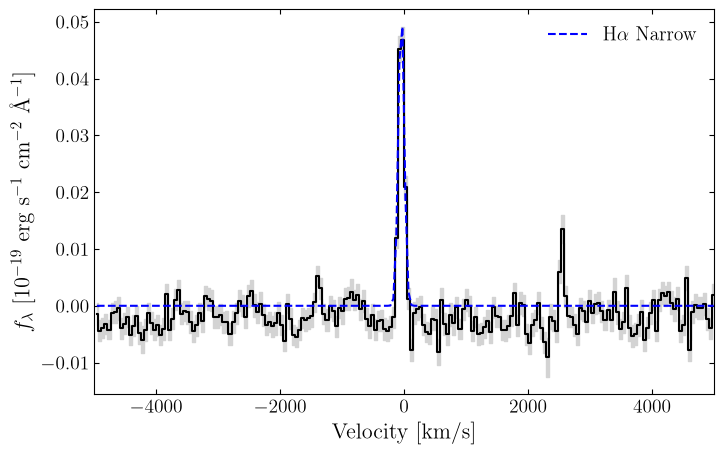

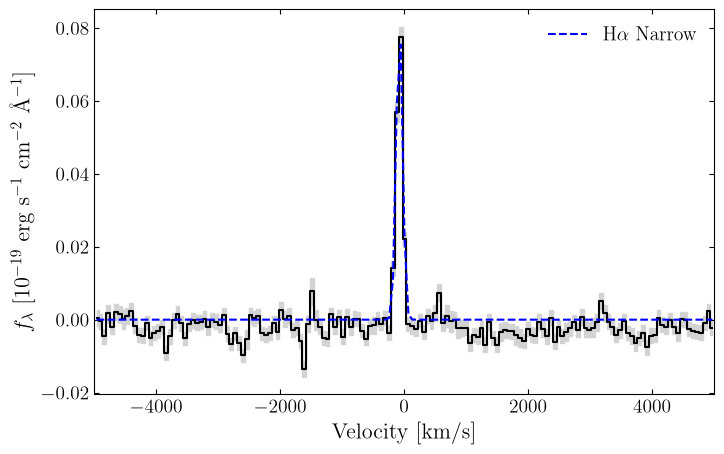

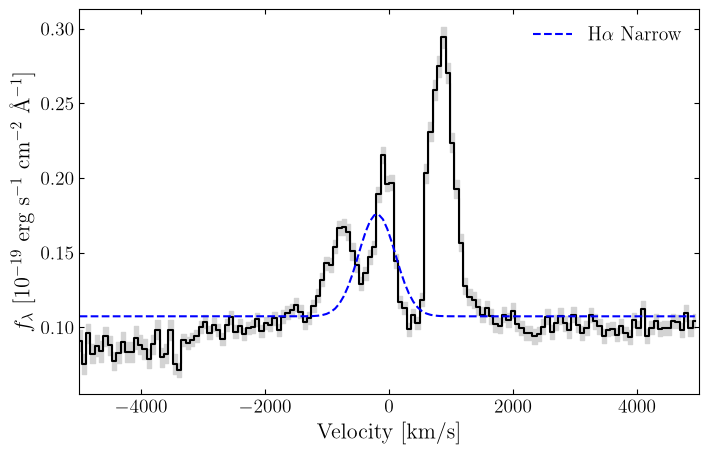

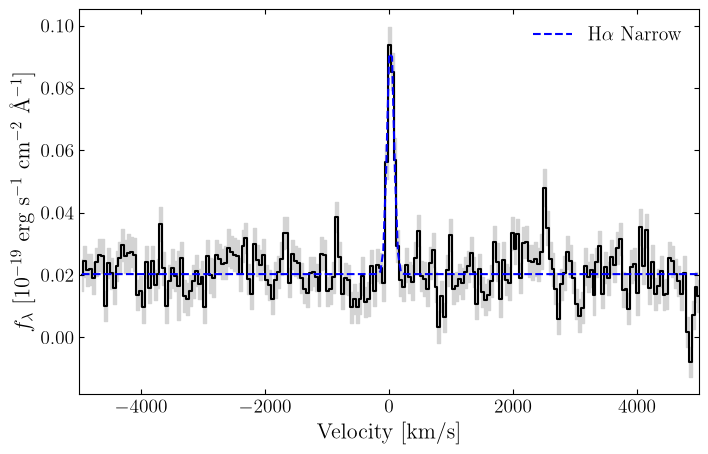

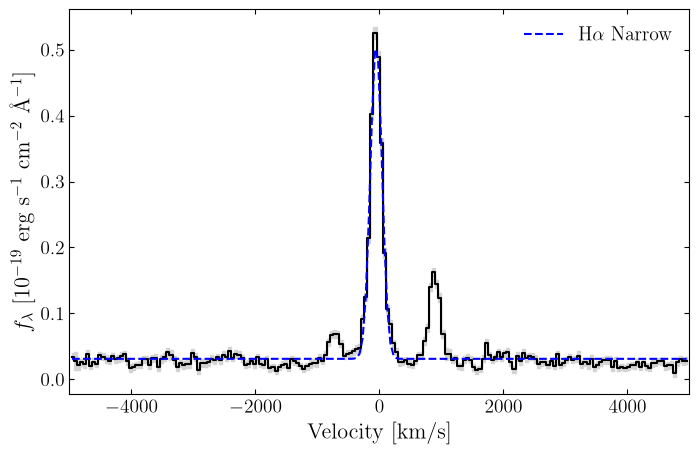

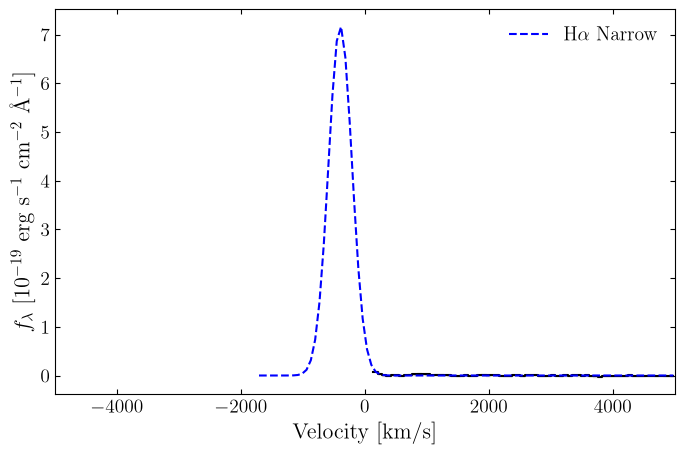

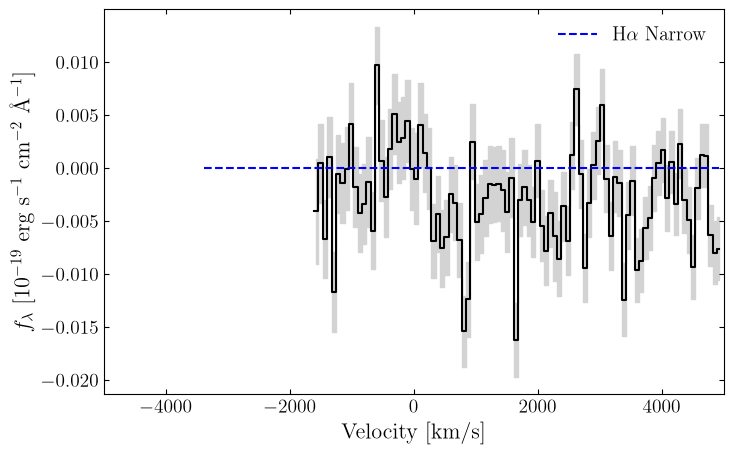

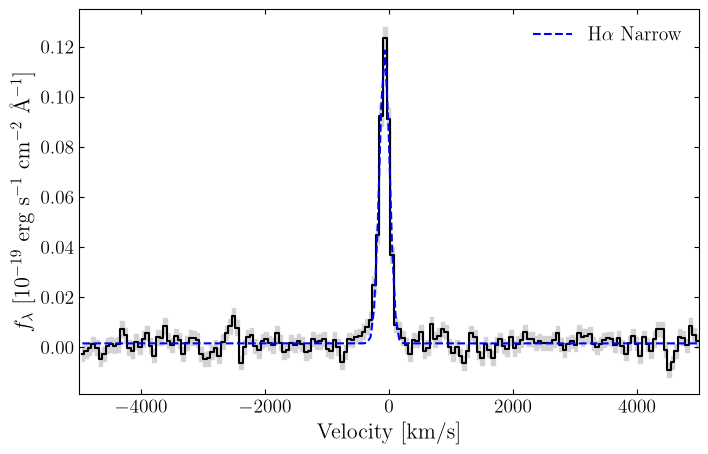

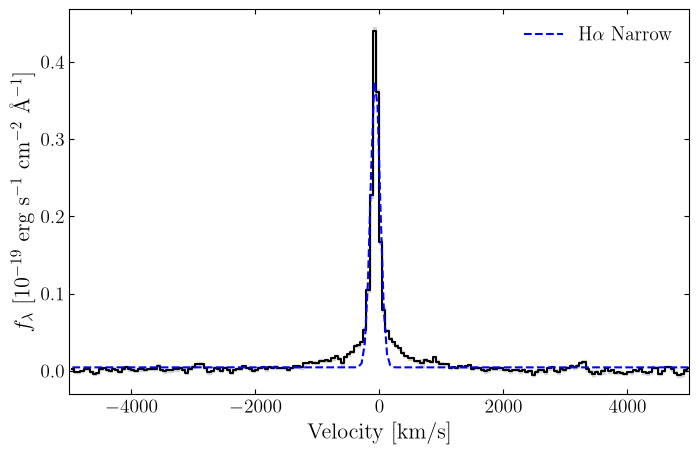

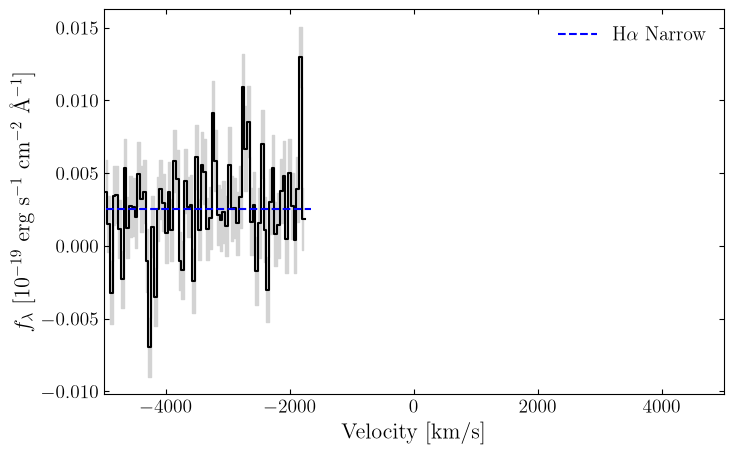

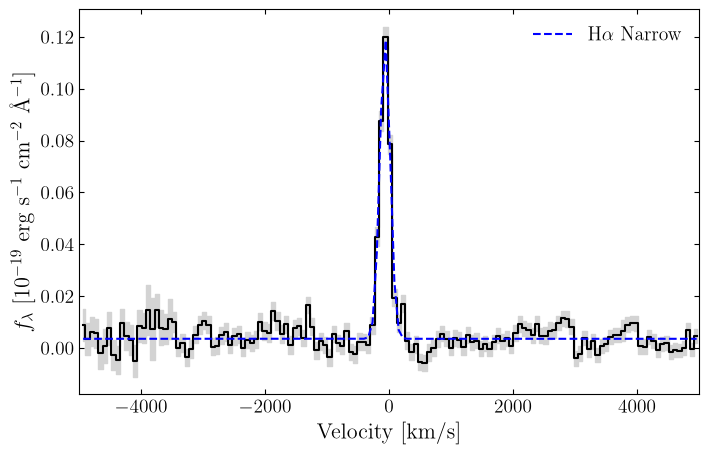

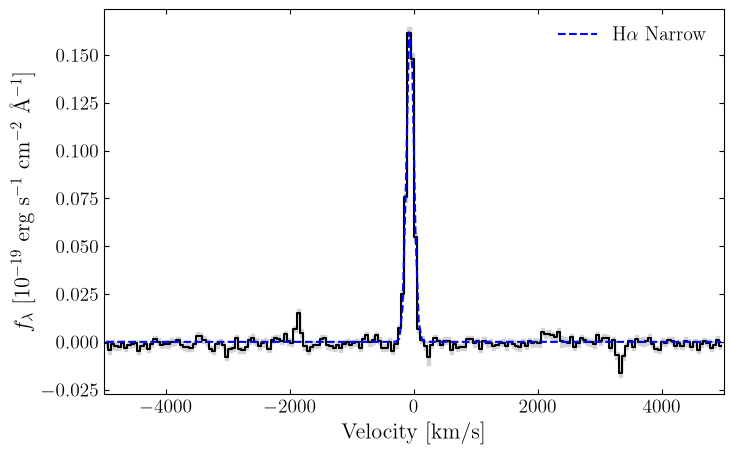

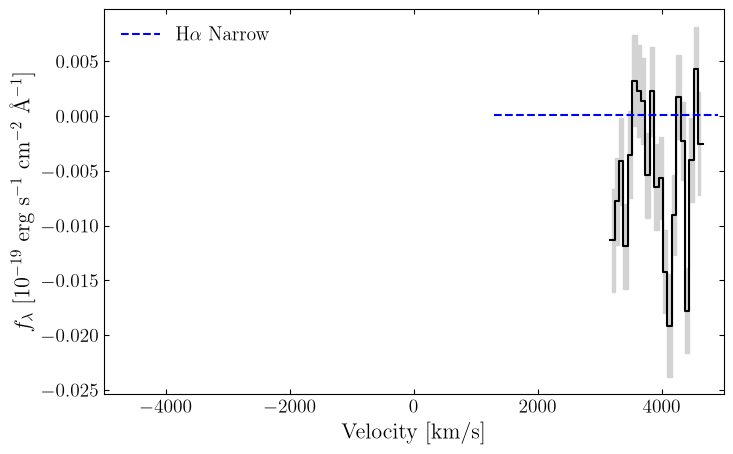

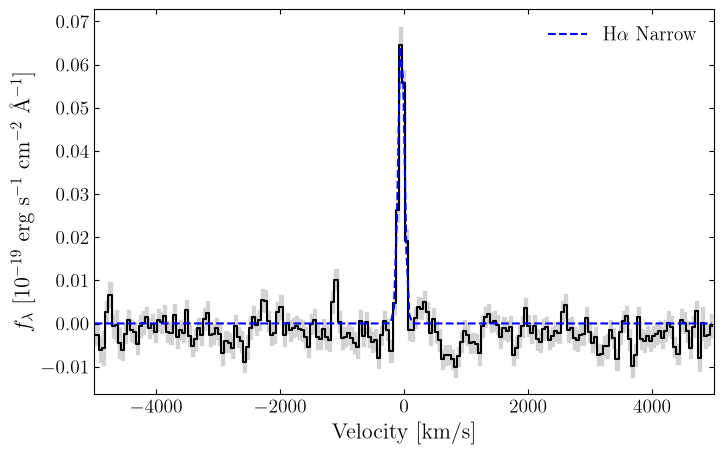

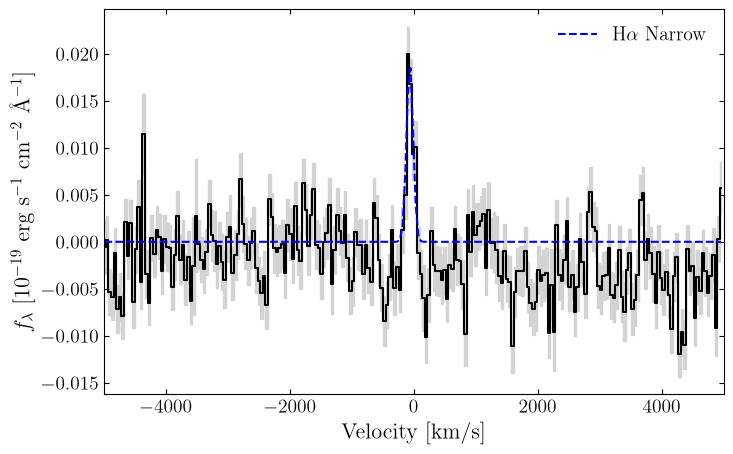

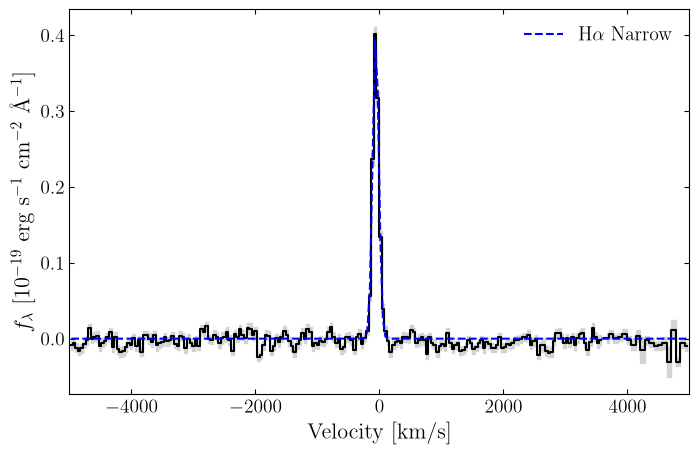

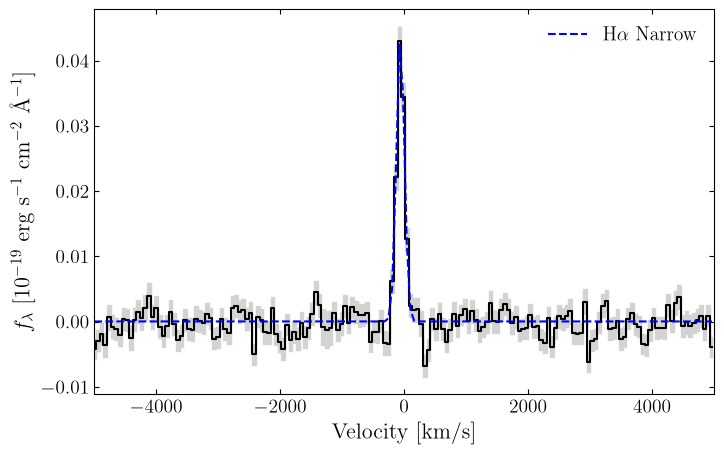

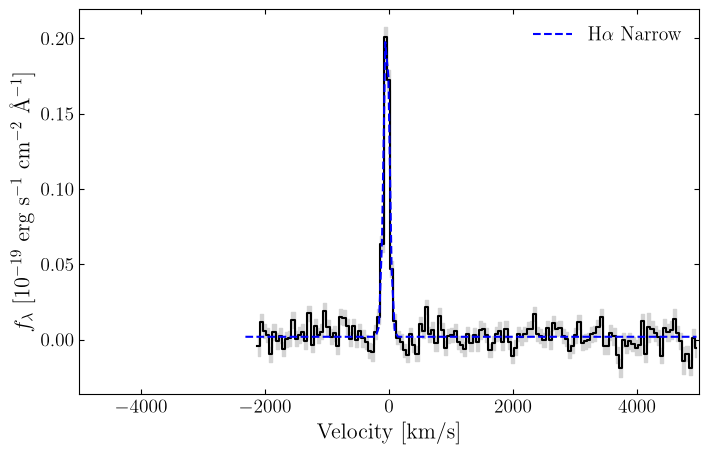

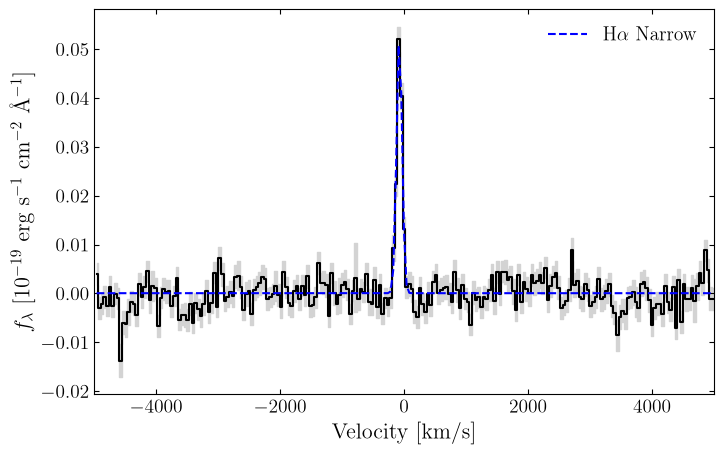

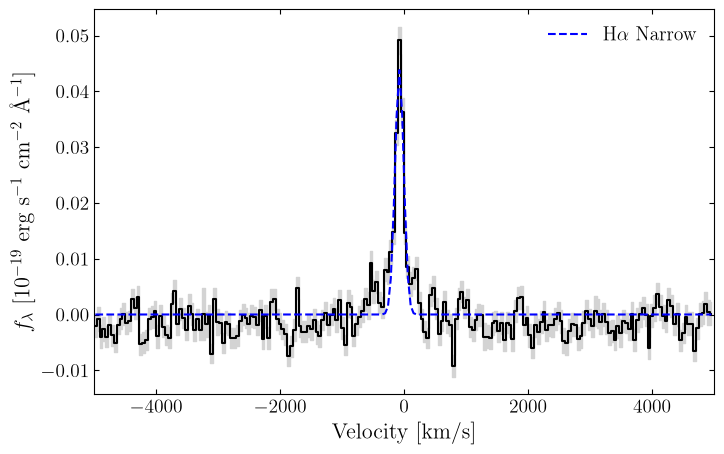

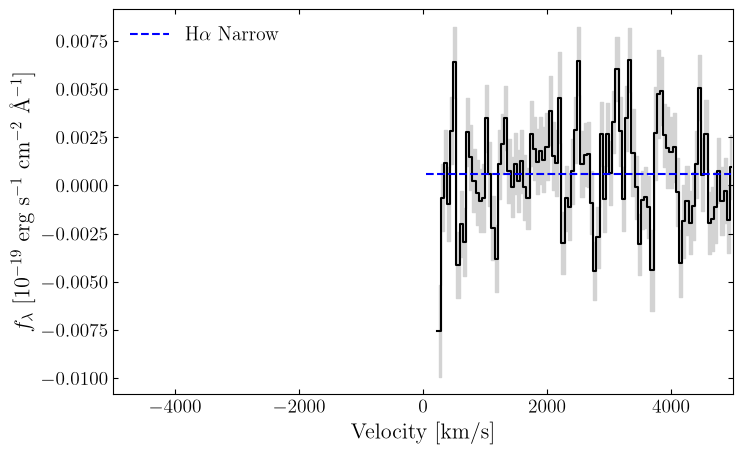

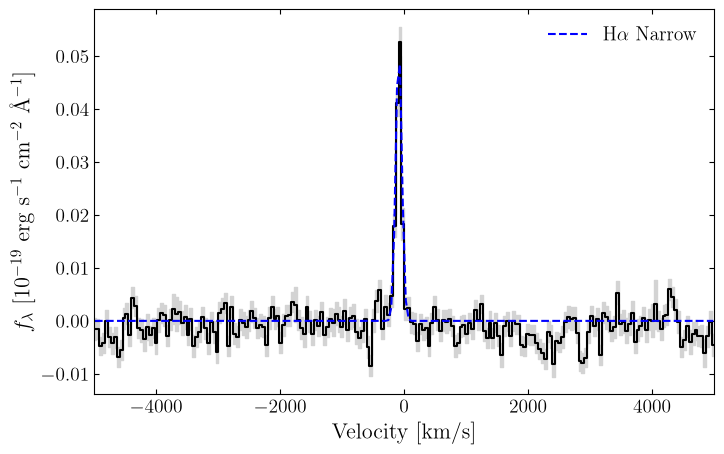

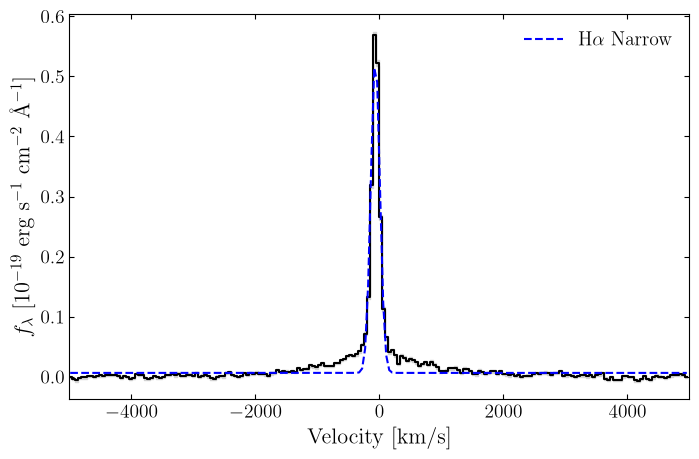

In [ ]:
## loop through the catalog and find the path to the file for each source 
data_direc = "/Users/madisynbrooks/Documents/OCEANS/Data/v0.5/x1d"
background = "mb" ## set backgroun to mb for master or nodded for local 

ha_direc = '/Users/madisynbrooks/Documents/OCEANS/Emission Line Fitting/halpha fits'

for row in oceans_redshifts:
    oceans_id = str(int(row['oceans_id'])).zfill(9) ## source ids are 9 numbers long with leading zeros
    z = row['zspec']
    spectra_name = f"s{oceans_id}"
    print(spectra_name)

    search_pattern = os.path.join(data_direc, "**", f"s{oceans_id}_{background}_*.fits")
    file_path = glob.glob(search_pattern, recursive=True)

    if len(file_path) > 1:
        ## need to name the files differently if they are observed in. more than one pointing
        ## so they don't overwrite each other yay! 


        print(f"source {oceans_id} found in more than one pointing")
    wv, fnu, fnu_err, flam, flam_err = astro_functions.load_1d_spec(file_path[0])
    wv_obs = wv / (1+z) ## convert to rest frame wavelength 


    ## check if the spectra has halpha coverage, if not continue
    line_obs = (1+z)*ha_line
    if g235h_wv_range[0] < line_obs < g395h_wv_range[1]:
        ## now we are going to run the narrow line only fit for each emission line 
        narrow_fit_ha(wv, flam, flam_err, z, spectra_name, ha_direc, plot_spec = True)
    else:
        print("No halpha wv coverage... ")
        print("-" * 30)

        continue 


    print("-" * 30)

In [12]:
wv

<Quantity [1.65541589, 1.65581727, 1.65621853, ..., 4.84797096, 4.8486228 ,
           4.84927845] um>